# 05 - LLM & RAG - Question Answering over WHO Malaria Documents

**Business context.** A national malaria control programme (Ministry of Health) relies on two large WHO documents to make decisions:
the *WHO guidelines for malaria* (494 pages of recommendations on prevention, vector control, chemoprevention, vaccines and case
management) and the *World malaria report 2025* (212 pages of burden, funding and intervention-coverage statistics, plus its
21-page executive summary). Programme staff currently search these PDFs manually every time they draft a policy brief, prepare a
budget justification or answer a question from a district team.

**Persona.** Head of a National Malaria Control Programme. They need fast answers **with the document and page cited**, so that
every statement can be checked before it reaches a policy brief. In this setting a confident but wrong answer is worse than
"I could not find it": a fabricated dosage or statistic that slips into an official document has a much higher cost than the
few minutes needed to look something up manually.

**Business question.** Can a Retrieval-Augmented Generation (RAG) assistant built on these WHO documents answer the programme's
questions faithfully enough to replace manual PDF search for routine look-ups, and does a free, locally run embedding model
retrieve the right passages as well as OpenAI's paid embedding model?

**Hypotheses (stated before building or evaluating anything):**

| # | Hypothesis | How it is tested |
|---|---|---|
| H1 | OpenAI `text-embedding-3-small` retrieves better than the local `BAAI/bge-small-en-v1.5` model | hit rate@5 and MRR@5 on a hand-labelled evaluation set (section 6.2) |
| H2 | RAG answers are more often correct than closed-book answers from the same LLM, especially for World malaria report 2025 statistics | AI-judge correctness by configuration and question category (section 8.2) |
| H3 | Hybrid search (BM25 + dense, fused with Reciprocal Rank Fusion) beats the best dense-only retriever | hit rate@5 and MRR@5 (section 6.3) |
| H4 | With a grounding prompt, RAG correctly abstains on questions the documents cannot answer more often than the closed-book LLM | abstention rate on unanswerable questions (section 8.3) |

**Reference framework.** The pipeline and its evaluation follow *AI Engineering* (Chip Huyen, 2025), chapter 6 (RAG) and
chapters 3-4 (evaluation): a RAG system is a **retriever** (indexing + querying) plus a **generator**; term-based (BM25) and
embedding-based retrieval are compared and combined (hybrid search with RRF); and the system is evaluated **component by
component and end to end**: retrieval quality first, then answer correctness, **local factual consistency** (faithfulness to the
retrieved context) and abstention, using an AI judge with categorical labels and an explicit rubric.

## Notebook Roadmap

1. **Setup**: libraries, configuration, API key check, LLM response cache
2. **Corpus Acquisition & Understanding**: download, page/character profile, PDF extraction quality
3. **Chunking**: strategy, chunk size and token distribution, embedding cost estimate
4. **Indexing**: local embeddings, OpenAI embeddings, Chroma vector store summary
5. **Evaluation Set**: design, categories, automatic evidence-to-page mapping
6. **Retrieval Evaluation**: BM25 baseline, dense local vs. OpenAI (H1), hybrid RRF (H3), results by category
7. **Generation**: grounding prompt, LangChain RAG chain, closed-book baseline, side-by-side examples
8. **Answer Evaluation**: AI-judge rubric, correctness and faithfulness (H2), abstention (H4), judge sanity check, citation quality, latency and cost
9. **Error Analysis**: retrieval failures vs. generation failures
10. **Business Storytelling & Key Findings**: assistant demo, hypotheses and results, recommendation
11. **Conclusions & Next Steps**

## 1. Setup

Libraries, model names, prices and paths. The OpenAI API key is loaded from a `.env` file (never committed); the notebook only
checks that it exists and never prints it.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
os.environ["ANONYMIZED_TELEMETRY"] = "False"          # Chroma telemetry off
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"

import re
import json
import time
import hashlib
import shutil
import urllib.request
from pathlib import Path
from typing import Literal
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from dotenv import load_dotenv, find_dotenv
from pypdf import PdfReader
import tiktoken
from rank_bm25 import BM25Okapi
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from pydantic import BaseModel, Field

import transformers
from huggingface_hub.utils import logging as hf_logging
transformers.logging.set_verbosity_error()
transformers.logging.disable_progress_bar()
hf_logging.set_verbosity_error()

from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_chroma import Chroma

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Paths (the notebook runs from notebooks/, but also works from the project root)
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_RAW = PROJECT_DIR / "data" / "raw"
DATA_PROCESSED = PROJECT_DIR / "data" / "processed"
EVAL_PATH = PROJECT_DIR / "eval" / "eval_questions.csv"
CHROMA_DIR = DATA_PROCESSED / "chroma"
for p in (DATA_RAW, DATA_PROCESSED):
    p.mkdir(parents=True, exist_ok=True)

# API key: repository-root .env locally, environment variable in CI
load_dotenv(find_dotenv(usecwd=True))
assert os.getenv("OPENAI_API_KEY"), "OPENAI_API_KEY not found (.env at the repository root or environment variable)."

# Models
GEN_MODEL = "gpt-4.1-mini"            # generator (cheap, supports temperature=0)
JUDGE_MODEL = "gpt-4.1"               # judge: a different, larger model than the generator, to limit self-bias
OPENAI_EMB_MODEL = "text-embedding-3-small"
LOCAL_EMB_MODEL = "BAAI/bge-small-en-v1.5"
BGE_QUERY_PREFIX = "Represent this sentence for searching relevant passages: "

# OpenAI list prices in USD per 1M tokens at the time of writing (assumption: update if prices change)
PRICES = {
    "gpt-4.1-mini": {"input": 0.40, "output": 1.60},
    "gpt-4.1": {"input": 2.00, "output": 8.00},
    "text-embedding-3-small": {"input": 0.02, "output": 0.0},
}

sns.set_style("whitegrid")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

print("Project dir:", PROJECT_DIR.name)
print("OpenAI API key loaded:", bool(os.getenv("OPENAI_API_KEY")))
print("Generator:", GEN_MODEL, "| Judge:", JUDGE_MODEL)
print("Embeddings:", OPENAI_EMB_MODEL, "vs.", LOCAL_EMB_MODEL)

Project dir: 05_llm_rag_pdf_chatbot
OpenAI API key loaded: True
Generator: gpt-4.1-mini | Judge: gpt-4.1
Embeddings: text-embedding-3-small vs. BAAI/bge-small-en-v1.5


**Response cache.** Every chat-model response is saved in `data/processed/llm_cache.json`, keyed by the model and the exact
prompt, so re-running the notebook reproduces the same answers and judgments without paying for them again.

In [2]:
# --- LLM response cache -----------------------------------------------------
CACHE_PATH = DATA_PROCESSED / "llm_cache.json"
LLM_CACHE = json.loads(CACHE_PATH.read_text(encoding="utf-8")) if CACHE_PATH.exists() else {}


def cache_key(*parts):
    return hashlib.sha256(json.dumps(parts, sort_keys=True, ensure_ascii=False).encode("utf-8")).hexdigest()


def save_cache():
    CACHE_PATH.write_text(json.dumps(LLM_CACHE, ensure_ascii=False), encoding="utf-8")


CHAT_MODELS = {m: ChatOpenAI(model=m, temperature=0, seed=RANDOM_STATE, max_retries=6, timeout=120)
               for m in (GEN_MODEL, JUDGE_MODEL)}


def chat(model, messages):
    """Call a chat model (temperature 0) with caching; returns content, token usage and the original latency."""
    key = cache_key("chat", model, [(m.type, m.content) for m in messages])
    if key not in LLM_CACHE:
        t0 = time.perf_counter()
        resp = CHAT_MODELS[model].invoke(messages)
        LLM_CACHE[key] = {
            "content": resp.content,
            "input_tokens": resp.usage_metadata["input_tokens"],
            "output_tokens": resp.usage_metadata["output_tokens"],
            "latency_s": time.perf_counter() - t0,
        }
    return LLM_CACHE[key]


def llm_cost(model, input_tokens, output_tokens):
    return (input_tokens * PRICES[model]["input"] + output_tokens * PRICES[model]["output"]) / 1e6


print(f"Cached LLM responses available: {len(LLM_CACHE)}")

Cached LLM responses available: 801


## 2. Corpus Acquisition & Understanding

### 2.1 Download

The three PDFs are public WHO publications (licence CC BY-NC-SA 3.0 IGO), downloaded straight from WHO's repositories into
`data/raw/` and only fetched when the file is not already present.

In [3]:
DOCS = {
    "who_guidelines_malaria": {
        "label": "WHO Guidelines for malaria",
        "url": "https://iris.who.int/server/api/core/bitstreams/d3c6488b-3ee6-41cb-960f-ddf0202cd74d/content",
    },
    "world_malaria_report_2025": {
        "label": "World malaria report 2025",
        "url": "https://iris.who.int/server/api/core/bitstreams/be20b8dc-cbfa-42a6-ad17-7679ceb75360/content",
    },
    "wmr_2025_executive_summary": {
        "label": "WMR 2025 executive summary",
        "url": ("https://cdn.who.int/media/docs/default-source/malaria/world-malaria-reports/"
                "world-malaria-report-2025-executive-summary-eng.pdf?sfvrsn=154ea8d5_26&download=true"),
    },
}

for doc_id, meta in DOCS.items():
    path = DATA_RAW / f"{doc_id}.pdf"
    if not path.exists():
        req = urllib.request.Request(meta["url"], headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=300) as r:
            path.write_bytes(r.read())
        print(f"Downloaded {path.name}")
    meta["path"] = path
    print(f"{path.name:<35} {path.stat().st_size / 1e6:6.1f} MB")

who_guidelines_malaria.pdf             3.5 MB
world_malaria_report_2025.pdf         11.5 MB
wmr_2025_executive_summary.pdf         6.5 MB


### 2.2 Page and character profile

Before chunking anything, each PDF is profiled page by page: how much text `pypdf` extracts per page and how many pages are
empty or nearly empty (covers, separators, full-page maps or charts with no text layer).

                            pages  total_chars  median_chars_per_page  near_empty_pages
doc                                                                                    
who_guidelines_malaria        494      1920279                 3947.5                 1
world_malaria_report_2025     212       677601                 2790.0                 9
wmr_2025_executive_summary     21        32725                 1513.0                 2

Total: 727 pages, 2,630,605 characters


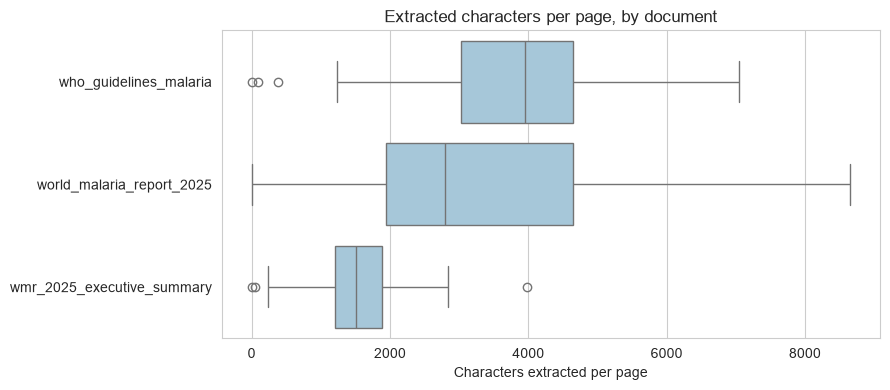

In [4]:
raw_pages = []
for doc_id, meta in DOCS.items():
    for i, page in enumerate(PdfReader(meta["path"]).pages, start=1):
        raw_pages.append({"doc": doc_id, "page": i, "raw_text": page.extract_text() or ""})
pages_df = pd.DataFrame(raw_pages)
pages_df["raw_chars"] = pages_df["raw_text"].str.len()

profile = (pages_df.groupby("doc")
           .agg(pages=("page", "count"),
                total_chars=("raw_chars", "sum"),
                median_chars_per_page=("raw_chars", "median"),
                near_empty_pages=("raw_chars", lambda s: int((s < 50).sum())))
           .loc[list(DOCS)])
print(profile.to_string())
print(f"\nTotal: {profile['pages'].sum()} pages, {profile['total_chars'].sum():,} characters")

fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=pages_df, x="raw_chars", y="doc", order=list(DOCS), ax=ax, color="#9ecae1")
ax.set_xlabel("Characters extracted per page")
ax.set_ylabel("")
ax.set_title("Extracted characters per page, by document")
plt.tight_layout()
plt.show()

### 2.2 Results - Corpus size and page profile

| Document | Pages | Characters extracted | Median characters / page | Near-empty pages (< 50 chars) |
|---|---|---|---|---|
| WHO guidelines for malaria | 494 | 1,920,279 | 3,947.5 | 1 |
| World malaria report 2025 | 212 | 677,601 | 2,790.0 | 9 |
| WMR 2025 executive summary | 21 | 32,725 | 1,513.0 | 2 |
| **Total** | **727** | **2,630,605** | | **12** |

- The corpus is dominated by the guidelines: 73.0% of all extracted characters (1,920,279 of 2,630,605) come from a single
  document, so any retriever will mostly be searching guideline text.
- The guidelines are text-dense (median 3,947.5 characters per page), while the World malaria report has a lower median
  (2,790.0) because many of its pages are charts, maps and tables. The executive summary is the sparsest (1,513.0), since it is a
  designed brochure with one or two short paragraphs per page around large figures.
- Only 12 of the 727 pages are near-empty (covers, separators and full-page figures without a text layer), 9 of them in the World
  malaria report. Extraction works on every document, but the boxplot shows that the report and the executive summary carry much
  less text per page, which matters for questions whose answer sits inside a figure.

### 2.3 Extraction quality and cleaning

PDF text extraction is never perfect. Two systematic artefacts were found by inspecting the raw text:

- **Chart glyph names.** In the executive summary, chart axis labels are extracted as font glyph names (`/two.tnum /zero.tnum`)
  instead of digits. They carry no meaning for retrieval and would pollute both BM25 and the embeddings.
- **Repeated page footer.** Every page of the guidelines ends with the same footer
  (`WHO guidelines for malaria - <date> - World Health Organization (WHO) <n> of 494`), repeated 494 times.

Both are removed, runs of whitespace are collapsed, and pages with fewer than 50 characters left are dropped.

In [5]:
GLYPH_RE = re.compile(r"/[a-z]+\.tnum")
FOOTER_RE = re.compile(r"WHO guidelines for malaria - \d+ \w+ \d{4} - World Health Organization \(WHO\)\s*\d+ of \d+")


def clean_text(text):
    text = GLYPH_RE.sub("", text)
    text = FOOTER_RE.sub("", text)
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()


pages_df["glyph_tokens"] = pages_df["raw_text"].str.count(GLYPH_RE.pattern)
pages_df["footers"] = pages_df["raw_text"].str.count(FOOTER_RE.pattern)
pages_df["text"] = pages_df["raw_text"].map(clean_text)
pages_df["chars"] = pages_df["text"].str.len()

quality = (pages_df.groupby("doc")
           .agg(glyph_tokens=("glyph_tokens", "sum"),
                footers_removed=("footers", "sum"),
                raw_chars=("raw_chars", "sum"),
                clean_chars=("chars", "sum"),
                pages_dropped=("chars", lambda s: int((s < 50).sum())))
           .loc[list(DOCS)])
quality["chars_removed_pct"] = (100 * (1 - quality["clean_chars"] / quality["raw_chars"])).round(2)
print(quality.to_string())

example = pages_df.query("doc == 'wmr_2025_executive_summary' and page == 4")["raw_text"].iloc[0]
print("\nRaw extraction sample (executive summary, page 4):")
print(example[example.find("/two"):][:160].replace("\n", " "))

pages_df = pages_df[pages_df["chars"] >= 50].reset_index(drop=True)
print(f"\nPages kept for indexing: {len(pages_df)}")

                            glyph_tokens  footers_removed  raw_chars  clean_chars  pages_dropped  chars_removed_pct
doc                                                                                                                
who_guidelines_malaria                 0              493    1920279      1875030              2               2.36
world_malaria_report_2025            207                0     677601       673563              9               0.60
wmr_2025_executive_summary           252                0      32725        30191              2               7.74

Raw extraction sample (executive summary, page 4):
/two.tnum /five.tnum/zero.tnum/zero.tnum /two.tnum /zero.tnum/zero.tnum/zero.tnum /one.tnum /five.tnum/zero.tnum/zero.tnum /one.tnum /zero.tnum/zero.tnum/zero.t

Pages kept for indexing: 714


### 2.3 Results - Extraction artefacts removed

| Document | Glyph-name tokens | Footers removed | Characters before | Characters after | Removed | Pages dropped |
|---|---|---|---|---|---|---|
| WHO guidelines for malaria | 0 | 493 | 1,920,279 | 1,875,030 | 2.36% | 2 |
| World malaria report 2025 | 207 | 0 | 677,601 | 673,563 | 0.60% | 9 |
| WMR 2025 executive summary | 252 | 0 | 32,725 | 30,191 | 7.74% | 2 |

- The sample from page 4 of the executive summary shows the problem clearly: a chart axis such as "2 500, 2 000, 1 500" is
  extracted as `/two.tnum /five.tnum/zero.tnum/zero.tnum ...`. There were 252 such tokens in the executive summary and 207 in the
  report, and removing them took out 7.74% of the executive summary's characters. Left in place, they would have been indexed as
  meaningless "words" and diluted both the BM25 statistics and the embeddings of those pages.
- The repeated footer appeared on 493 of the 494 guideline pages (2.36% of the guidelines' characters). Because it is identical on
  every page, it would have made every guideline chunk look slightly similar to every other one.
- After cleaning, 714 pages remain for indexing (13 pages with fewer than 50 characters were dropped).

## 3. Chunking

### 3.1 Strategy

Documents are split **recursively** (paragraph, then line, then sentence,
then word boundaries) into chunks of at most **1,000 characters with 150 characters of overlap**:

- **Recursive splitting** reduces the chance of cutting a recommendation in the middle of a sentence, compared with fixed-length
  windows.
- **1,000 characters** (roughly 200-250 tokens) keeps each chunk focused on one recommendation or one statistic, while fitting
  well inside the 512-token limit of the local embedding model (checked in 3.2). Five retrieved chunks give the generator about
  1,200 tokens of context.
- **Overlap** ensures that a fact sitting on a chunk boundary appears complete in at least one chunk.
- Chunks never cross pages, so each chunk inherits an exact **page number for citation**. Page numbers are the PDF page index
  (as shown by a PDF viewer), which for the World malaria report differs from the printed page number.

In [6]:
CHUNK_SIZE, CHUNK_OVERLAP = 1000, 150

page_docs = [Document(page_content=r.text, metadata={"doc": r.doc, "page": int(r.page)})
             for r in pages_df.itertuples()]
splitter = RecursiveCharacterTextSplitter(chunk_size=CHUNK_SIZE, chunk_overlap=CHUNK_OVERLAP)
chunks = splitter.split_documents(page_docs)
for i, c in enumerate(chunks):
    c.metadata["chunk_id"] = f"c{i:05d}"

chunk_df = pd.DataFrame({
    "chunk_id": [c.metadata["chunk_id"] for c in chunks],
    "doc": [c.metadata["doc"] for c in chunks],
    "page": [c.metadata["page"] for c in chunks],
    "text": [c.page_content for c in chunks],
})
chunk_df["chars"] = chunk_df["text"].str.len()
CHUNK_TEXT = dict(zip(chunk_df["chunk_id"], chunk_df["text"]))
CHUNK_META = chunk_df.set_index("chunk_id")[["doc", "page"]].to_dict("index")

print(f"Total chunks: {len(chunks)}")
print(chunk_df.groupby("doc").agg(chunks=("chunk_id", "count"), mean_chars=("chars", "mean"))
      .loc[list(DOCS)].round(0).to_string())

Total chunks: 3305
                            chunks  mean_chars
doc                                           
who_guidelines_malaria        2388       876.0
world_malaria_report_2025      874       859.0
wmr_2025_executive_summary      43       767.0


### 3.1 Results - Number of chunks

| Document | Chunks | Mean characters per chunk |
|---|---|---|
| WHO guidelines for malaria | 2,388 | 876 |
| World malaria report 2025 | 874 | 859 |
| WMR 2025 executive summary | 43 | 767 |
| **Total** | **3,305** | |

The 714 pages produced 3,305 chunks. The guidelines contribute 72.3% of them (2,388), consistent with their share of the text. The
mean chunk length (767 to 876 characters, below the 1,000 maximum) shows the recursive splitter is cutting at paragraph and
sentence boundaries rather than at the hard limit, which is the intended behaviour. The executive summary has only 43 chunks, so
any question answered there competes against more than 3,200 chunks from the two larger documents.

### 3.2 Chunk length in tokens

Embedding models truncate input beyond their context limit, silently discarding text. Chunks are therefore measured with both
tokenizers: `cl100k_base` (used by `text-embedding-3-small`, limit 8,191 tokens) and the WordPiece tokenizer of
`bge-small-en-v1.5` (limit 512 tokens).

                mean    50%    95%    99%    max
tokens_openai  216.3  206.0  341.0  533.0  677.0
tokens_bge     202.5  199.0  292.0  488.8  872.0

Chunks above the 512-token bge limit: 27 (0.82%)


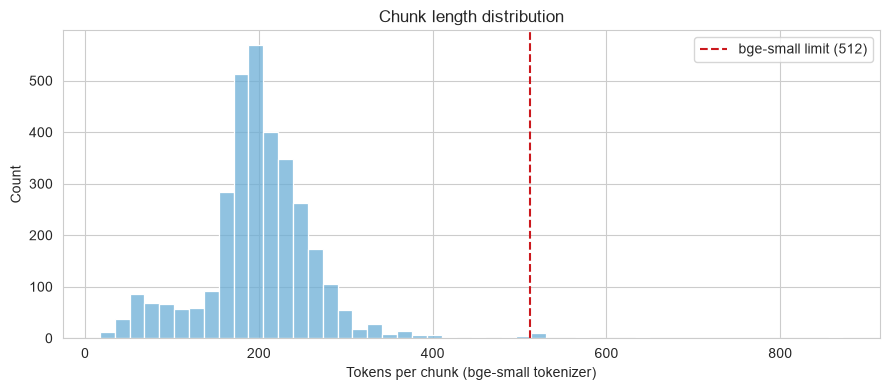

In [7]:
enc = tiktoken.get_encoding("cl100k_base")
chunk_df["tokens_openai"] = [len(enc.encode(t)) for t in chunk_df["text"]]

local_emb = HuggingFaceEmbeddings(
    model_name=LOCAL_EMB_MODEL,
    model_kwargs={"device": "cpu"},
    encode_kwargs={"normalize_embeddings": True, "batch_size": 32},
    query_encode_kwargs={"normalize_embeddings": True, "prompt": BGE_QUERY_PREFIX},
)
bge_tokenizer = local_emb._client.tokenizer
chunk_df["tokens_bge"] = [len(ids) for ids in bge_tokenizer(chunk_df["text"].tolist(), add_special_tokens=True)["input_ids"]]

token_stats = chunk_df[["tokens_openai", "tokens_bge"]].describe(percentiles=[0.5, 0.95, 0.99]).T
token_stats = token_stats[["mean", "50%", "95%", "99%", "max"]].round(1)
print(token_stats.to_string())
print(f"\nChunks above the 512-token bge limit: {(chunk_df['tokens_bge'] > 512).sum()} "
      f"({100 * (chunk_df['tokens_bge'] > 512).mean():.2f}%)")

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(chunk_df["tokens_bge"], bins=50, ax=ax, color="#6baed6")
ax.axvline(512, color="#cb181d", ls="--", label="bge-small limit (512)")
ax.set_xlabel("Tokens per chunk (bge-small tokenizer)")
ax.set_title("Chunk length distribution")
ax.legend()
plt.tight_layout()
plt.show()

### 3.2 Results - Chunk token distribution

| Tokenizer | Mean | Median | 95th percentile | 99th percentile | Max |
|---|---|---|---|---|---|
| `cl100k_base` (OpenAI) | 216.3 | 206.0 | 341.0 | 533.0 | 677.0 |
| `bge-small` WordPiece | 202.5 | 199.0 | 292.0 | 488.8 | 872.0 |

- A typical chunk is about 200 tokens with either tokenizer, so 1,000 characters is comfortably inside both models' limits.
- Only **27 chunks (0.82%) exceed the 512-token limit of `bge-small`** and are truncated by the local model. These are the
  number-heavy chunks (the histogram's long right tail up to 872 tokens): tables of figures such as "238 000 221 000 258 000"
  split into many tokens. Truncation therefore affects a small, specific part of the corpus (tables), not the guideline text.
- OpenAI's limit of 8,191 tokens is never reached (maximum 677).

### 3.3 Embedding cost estimate

Embedding cost scales with the number of tokens indexed, so it can be estimated before any API call.

In [8]:
total_tokens = int(chunk_df["tokens_openai"].sum())
openai_index_cost = total_tokens * PRICES[OPENAI_EMB_MODEL]["input"] / 1e6
print(f"Tokens to embed: {total_tokens:,}")
print(f"Estimated cost with {OPENAI_EMB_MODEL}: US$ {openai_index_cost:.4f}")
print(f"Estimated cost with {LOCAL_EMB_MODEL}: US$ 0 (local CPU)")

Tokens to embed: 714,802
Estimated cost with text-embedding-3-small: US$ 0.0143
Estimated cost with BAAI/bge-small-en-v1.5: US$ 0 (local CPU)


### 3.3 Results - Indexing cost

The full corpus is **714,802 tokens**. Embedding it with `text-embedding-3-small` costs an estimated **US\$ 0.0143**, about one
and a half cents for 727 pages, while the local model costs nothing in API fees. At this corpus size, embedding cost is not a
decision factor: the real trade-offs between the two models are indexing time, query latency and retrieval quality, measured
next.

## 4. Indexing

Indexing has two steps: **embedding** every chunk (the expensive part) and **storing** the vectors in a vector database. Each
embedding model gets its own **Chroma** collection (cosine distance, HNSW index), persisted to `data/processed/chroma/`.

Chunk embeddings are also saved to `data/processed/emb_<name>.npy`, keyed by a hash of the chunk texts, so a re-run reloads
them instead of re-embedding the whole corpus; they are recomputed automatically whenever the chunks change. The original
embedding time is stored in `index_stats.json`, so the reported indexing time is the real one even when the vectors come from
disk.

In [9]:
INDEX_STATS_PATH = DATA_PROCESSED / "index_stats.json"
INDEX_STATS = json.loads(INDEX_STATS_PATH.read_text()) if INDEX_STATS_PATH.exists() else {}
PROGRESS_LOG = DATA_PROCESSED / "index_progress.log"
CHUNKS_HASH = cache_key("chunks", [c.page_content for c in chunks])


def embed_chunks(name, embedding, batch_size=128):
    """Embed all chunk texts once and cache the matrix on disk."""
    npy_path = DATA_PROCESSED / f"emb_{name}.npy"
    stats = INDEX_STATS.get(name, {})
    if npy_path.exists() and stats.get("chunks_hash") == CHUNKS_HASH:
        print(f"[{name}] loaded cached embeddings {npy_path.name}")
        return np.load(npy_path)
    texts = [c.page_content for c in chunks]
    vectors, t0 = [], time.perf_counter()
    for start in range(0, len(texts), batch_size):
        vectors.extend(embedding.embed_documents(texts[start:start + batch_size]))
        with open(PROGRESS_LOG, "a", encoding="utf-8") as log:
            log.write(f"{name} {min(start + batch_size, len(texts))}/{len(texts)} {time.perf_counter() - t0:.0f}s\n")
    matrix = np.asarray(vectors, dtype=np.float32)
    np.save(npy_path, matrix)
    INDEX_STATS[name] = {"seconds": time.perf_counter() - t0, "chunks": len(texts), "chunks_hash": CHUNKS_HASH}
    INDEX_STATS_PATH.write_text(json.dumps(INDEX_STATS, indent=2))
    print(f"[{name}] embedded {len(texts)} chunks in {INDEX_STATS[name]['seconds']:.1f} s")
    return matrix


def build_or_load_collection(name, embedding):
    matrix = embed_chunks(name, embedding)
    vs = Chroma(collection_name=name, embedding_function=embedding,
                persist_directory=str(CHROMA_DIR), collection_metadata={"hnsw:space": "cosine"})
    if vs._collection.count() == len(chunks) and INDEX_STATS[name].get("stored_hash") == CHUNKS_HASH:
        print(f"[{name}] loaded existing Chroma collection ({len(chunks)} chunks)")
        return vs
    vs.delete_collection()
    vs = Chroma(collection_name=name, embedding_function=embedding,
                persist_directory=str(CHROMA_DIR), collection_metadata={"hnsw:space": "cosine"})
    for start in range(0, len(chunks), 1000):
        batch = chunks[start:start + 1000]
        vs._collection.add(ids=[c.metadata["chunk_id"] for c in batch],
                           embeddings=matrix[start:start + 1000].tolist(),
                           documents=[c.page_content for c in batch],
                           metadatas=[c.metadata for c in batch])
    INDEX_STATS[name]["stored_hash"] = CHUNKS_HASH
    INDEX_STATS_PATH.write_text(json.dumps(INDEX_STATS, indent=2))
    print(f"[{name}] stored {vs._collection.count()} vectors in Chroma")
    return vs

### 4.1 Local embeddings (`BAAI/bge-small-en-v1.5`)

A 33M-parameter model from the BGE family, run on CPU through `sentence-transformers`. Documents are embedded as-is; queries
receive the instruction prefix recommended by the model authors for retrieval.

In [10]:
vs_local = build_or_load_collection("local_bge_small", local_emb)

[local_bge_small] loaded cached embeddings emb_local_bge_small.npy


[local_bge_small] loaded existing Chroma collection (3305 chunks)


### 4.2 OpenAI embeddings (`text-embedding-3-small`)

In [11]:
openai_emb = OpenAIEmbeddings(model=OPENAI_EMB_MODEL, max_retries=6)
vs_openai = build_or_load_collection("openai_te3_small", openai_emb)

[openai_te3_small] loaded cached embeddings emb_openai_te3_small.npy


[openai_te3_small] loaded existing Chroma collection (3305 chunks)


### 4.3 Index summary

In [12]:
def dir_size_mb(path):
    return sum(f.stat().st_size for f in Path(path).rglob("*") if f.is_file()) / 1e6

index_summary = pd.DataFrame([
    {"collection": "local_bge_small", "model": LOCAL_EMB_MODEL, "dim": len(local_emb.embed_query("test")),
     "chunks": vs_local._collection.count(), "build_seconds": INDEX_STATS["local_bge_small"]["seconds"],
     "cost_usd": 0.0},
    {"collection": "openai_te3_small", "model": OPENAI_EMB_MODEL, "dim": len(openai_emb.embed_query("test")),
     "chunks": vs_openai._collection.count(), "build_seconds": INDEX_STATS["openai_te3_small"]["seconds"],
     "cost_usd": openai_index_cost},
])
index_summary["chunks_per_second"] = index_summary["chunks"] / index_summary["build_seconds"]
print(index_summary.round(4).to_string(index=False))
print(f"\nChroma directory on disk: {dir_size_mb(CHROMA_DIR):.1f} MB (both collections)")

      collection                  model  dim  chunks  build_seconds  cost_usd  chunks_per_second
 local_bge_small BAAI/bge-small-en-v1.5  384    3305       813.3634    0.0000             4.0634
openai_te3_small text-embedding-3-small 1536    3305        39.6601    0.0143            83.3332

Chroma directory on disk: 79.2 MB (both collections)


### 4.3 Results - Indexing time, size and cost

| Collection | Model | Dimensions | Chunks | Embedding time | Chunks / second | Cost |
|---|---|---|---|---|---|---|
| `local_bge_small` | `BAAI/bge-small-en-v1.5` | 384 | 3,305 | 813.4 s | 4.06 | US\$ 0 |
| `openai_te3_small` | `text-embedding-3-small` | 1,536 | 3,305 | 39.7 s | 83.33 | US\$ 0.0143 |

- The local model needed **813.4 seconds** (13.6 minutes) to embed the corpus, **20.5 times longer** than the OpenAI API
  (39.7 seconds). For the programme this is a one-off cost: the index is built once and only
  updated when WHO publishes a new edition.
- OpenAI vectors are 4 times wider (1,536 vs. 384 dimensions); both collections together take 79.2 MB on disk, negligible
  for any deployment.
- The cost difference is US\$ 0.0143 per full re-index, which confirms that money is not what separates the two options.

## 5. Evaluation Set

### 5.1 Design

The evaluation set (`eval/eval_questions.csv`, versioned with the project) was written **by hand, reading the PDF pages, before
any retrieval or generation was run**, to avoid tailoring questions to what the system happens to retrieve. It has 45 questions
in three categories that mirror what the persona actually asks:

- `guideline_recommendation` (19): treatment, chemoprevention, vaccine and vector-control recommendations (plus one cost-model assumption, G19) from the guidelines.
- `report_statistic` (20): burden, funding, resistance and coverage figures from the World malaria report 2025 / executive summary.
  These are also the questions most likely to be outside the LLM's training data (the report was published in December 2025).
- `unanswerable` (6): plausible questions whose answer is **not** in the corpus (verified by full-text search), such as dengue
  vaccine dosing or a WHO position on gene drive mosquitoes. Questions about things that are not in the documents are where
  models hallucinate most, so they are the direct test of H4.

**One label was corrected after the first evaluation run.** Question G19 ("What is the price per dose of the R21/Matrix-M
malaria vaccine?") was originally written as unanswerable (U03), after a keyword search for phrases such as "price per dose" found
nothing. In the first run, all three RAG configurations answered "an assumed price of US\$ 3 per dose" and cited guidelines page
162, where a cost-effectiveness model indeed assumes "an assumed R21/Matrix-M vaccine price of US\$ 3 per dose". The gold label
was wrong, not the answers, so the question was moved to the answerable set with a reference answer that makes the "assumed, not
a market price" nuance explicit. No other question or label was changed after seeing results.

Each answerable question has a human-written `reference_answer`, one or more verbatim `evidence` phrases copied from the source,
and `key_terms` used later as a lexical, judge-independent check. A retrieved chunk counts as **relevant** when it contains an
evidence phrase (whitespace- and case-insensitive, because `pypdf` sometimes glues words together). This "answer-bearing passage"
definition handles facts repeated across documents (the executive summary restates the report) and across sections (the
guidelines repeat each recommendation in a summary and in a detailed section), which a single gold page would miss.

In [13]:
eval_df = pd.read_csv(EVAL_PATH).fillna("")


def norm_nospace(s):
    return re.sub(r"\s+", "", s).lower()


CHUNK_NORM = {cid: norm_nospace(t) for cid, t in CHUNK_TEXT.items()}


def evidence_phrases(row):
    return [norm_nospace(p) for p in row["evidence"].split("||") if p.strip()]


def relevant_chunks(row):
    phrases = evidence_phrases(row)
    return {cid for cid, t in CHUNK_NORM.items() if any(p in t for p in phrases)}


eval_df["relevant_chunks"] = eval_df.apply(relevant_chunks, axis=1)
eval_df["n_relevant_chunks"] = eval_df["relevant_chunks"].map(len)
eval_df["gold_pages"] = eval_df["relevant_chunks"].map(
    lambda ids: sorted({f"{DOCS[CHUNK_META[c]['doc']]['label']} p.{CHUNK_META[c]['page']}" for c in ids}))
answerable = eval_df["category"] != "unanswerable"
assert (eval_df.loc[answerable, "n_relevant_chunks"] > 0).all(), "Some evidence phrases are not found in any chunk"
assert (eval_df.loc[~answerable, "n_relevant_chunks"] == 0).all()

summary = (eval_df.groupby("category")
           .agg(questions=("qid", "count"),
                mean_relevant_chunks=("n_relevant_chunks", "mean"),
                max_relevant_chunks=("n_relevant_chunks", "max")))
print(summary.round(2).to_string())
print()
print(eval_df.loc[[0, 19, 39], ["qid", "question", "gold_pages"]].to_string(index=False))

                          questions  mean_relevant_chunks  max_relevant_chunks
category                                                                      
guideline_recommendation         19                  2.79                    8
report_statistic                 20                  3.55                    8
unanswerable                      6                  0.00                    0

qid                                                                                                                                  question                                                                                                                                                                                         gold_pages
G01 Which artemisinin-based combination therapies does WHO recommend for treating uncomplicated P. falciparum malaria in children and adults?                                                                                                                              

### 5.1 Results - Evaluation set overview

| Category | Questions | Mean relevant chunks per question | Max relevant chunks |
|---|---|---|---|
| guideline_recommendation | 19 | 2.79 | 8 |
| report_statistic | 20 | 3.55 | 8 |
| unanswerable | 6 | 0.00 | 0 |

- Every answerable question has at least one chunk containing its evidence (the notebook asserts this), and the 6 unanswerable
  questions have none, so the labels are consistent with the indexed text.
- Facts are repeated across the corpus: a guideline recommendation appears in 2.79 chunks on average (summary section and detailed
  section), a report statistic in 3.55 (report, executive summary and sometimes the guidelines' introduction). The printed example
  R01 (282 million cases) has evidence on 6 pages across all three documents, including page 31 of the guidelines, which quotes
  the World malaria report. A single "gold page" would have marked five of these six correct passages as misses.
- With 39 answerable questions, one question is worth 2.56 percentage points on any retrieval or answer metric, which is
  the right scale for reading the differences in the next sections.

## 6. Retrieval Evaluation

The retriever is evaluated on its own, before any generation, because a RAG system can only answer from what it retrieves.
Five retrievers are compared on the 39 answerable questions, each returning a ranked
list of 10 chunks:

| Retriever | Type |
|---|---|
| `bm25` | term-based (Okapi BM25 over lower-cased tokens, English stop words removed) |
| `dense_local` | embedding-based, `bge-small-en-v1.5` |
| `dense_openai` | embedding-based, `text-embedding-3-small` |
| `hybrid_local` | BM25 + `dense_local`, fused with Reciprocal Rank Fusion |
| `hybrid_openai` | BM25 + `dense_openai`, fused with Reciprocal Rank Fusion |

Metrics (all on answerable questions):
- **hit rate@k**: share of questions with at least one relevant chunk in the top k (k = 1, 3, 5). Hit rate@5 matters most,
  because the generator receives 5 chunks.
- **MRR@5**: mean reciprocal rank of the first relevant chunk within the top 5 (0 if none), rewarding relevant chunks ranked first.
- **context precision@5**: share of the top-5 chunks that are relevant ("context precision").
- **latency**: mean time to retrieve for one query.

In [14]:
TOP_K = 10      # retrieved per retriever
GEN_K = 5       # chunks passed to the generator
TOKEN_RE = re.compile(r"[a-z0-9]+(?:[.\-/][a-z0-9]+)*")


def bm25_tokenize(text):
    return [t for t in TOKEN_RE.findall(text.lower()) if t not in ENGLISH_STOP_WORDS]


chunk_ids = chunk_df["chunk_id"].tolist()
bm25 = BM25Okapi([bm25_tokenize(t) for t in chunk_df["text"]])


def retrieve_bm25(query, k=TOP_K):
    scores = bm25.get_scores(bm25_tokenize(query))
    return [chunk_ids[i] for i in np.argsort(scores)[::-1][:k]]


def retrieve_dense(vs, query, k=TOP_K):
    return [d.metadata["chunk_id"] for d in vs.similarity_search(query, k=k)]


def rrf(ranked_lists, k_const=60, k=TOP_K):
    """Reciprocal Rank Fusion: score(d) = sum over retrievers of 1 / (k_const + rank of d)."""
    scores = {}
    for ranked in ranked_lists:
        for rank, cid in enumerate(ranked, start=1):
            scores[cid] = scores.get(cid, 0.0) + 1.0 / (k_const + rank)
    return [cid for cid, _ in sorted(scores.items(), key=lambda x: x[1], reverse=True)[:k]]


RETRIEVERS = {
    "bm25": lambda q: retrieve_bm25(q),
    "dense_local": lambda q: retrieve_dense(vs_local, q),
    "dense_openai": lambda q: retrieve_dense(vs_openai, q),
    "hybrid_local": lambda q: rrf([retrieve_bm25(q, 20), retrieve_dense(vs_local, q, 20)]),
    "hybrid_openai": lambda q: rrf([retrieve_bm25(q, 20), retrieve_dense(vs_openai, q, 20)]),
}

# Retrieval results and their measured latency are stored on first run (like the index build time),
# so re-runs report the same rankings and timings; they are recomputed if the chunks or questions change.
RETRIEVAL_PATH = DATA_PROCESSED / "retrieval_runs.json"
RUN_KEY = cache_key(CHUNKS_HASH, eval_df["question"].tolist(), TOP_K)
stored = json.loads(RETRIEVAL_PATH.read_text()) if RETRIEVAL_PATH.exists() else {}
if stored.get("run_key") == RUN_KEY:
    retrieved, retrieval_latency = stored["retrieved"], stored["latency"]
    print("Loaded stored retrieval runs")
else:
    retrieved, retrieval_latency = {}, {}
    for name, fn in RETRIEVERS.items():
        retrieved[name], times = {}, []
        for row in eval_df.itertuples():
            t0 = time.perf_counter()
            retrieved[name][row.qid] = fn(row.question)
            times.append(time.perf_counter() - t0)
        retrieval_latency[name] = float(np.mean(times))
    RETRIEVAL_PATH.write_text(json.dumps({"run_key": RUN_KEY, "retrieved": retrieved, "latency": retrieval_latency}))
print("Retrieved top-10 chunks for", len(eval_df), "questions with", len(RETRIEVERS), "retrievers")

Loaded stored retrieval runs
Retrieved top-10 chunks for 45 questions with 5 retrievers


**Metric functions.** Hit rate@k, MRR@5, precision@5 and mean latency per retriever, computed on the answerable questions.

In [15]:
def retrieval_metrics(name, rows):
    hits = {1: [], 3: [], 5: []}
    rr, prec = [], []
    for row in rows.itertuples():
        ranked = retrieved[name][row.qid]
        rel = [cid in row.relevant_chunks for cid in ranked]
        for k in hits:
            hits[k].append(any(rel[:k]))
        first = next((i for i, r in enumerate(rel[:5], start=1) if r), None)
        rr.append(1 / first if first else 0.0)
        prec.append(np.mean(rel[:5]))
    return {"hit@1": np.mean(hits[1]), "hit@3": np.mean(hits[3]), "hit@5": np.mean(hits[5]),
            "MRR@5": np.mean(rr), "precision@5": np.mean(prec),
            "latency_ms": 1000 * retrieval_latency[name]}


ans_df = eval_df[answerable]
retrieval_results = pd.DataFrame({name: retrieval_metrics(name, ans_df) for name in RETRIEVERS}).T

### 6.1 Term-based baseline (BM25)

BM25 ranks chunks by how often the question's words appear in them, weighting rare words more. It is the classic term-based
baseline: no model, no API, and still hard to beat.

In [16]:
print(retrieval_results.loc[["bm25"]].round(4).to_string())

       hit@1   hit@3   hit@5   MRR@5  precision@5  latency_ms
bm25  0.5641  0.7179  0.8205  0.6611       0.3179     12.2202


### 6.1 Results - BM25 baseline

| Retriever | hit@1 | hit@3 | hit@5 | MRR@5 | precision@5 | latency |
|---|---|---|---|---|---|---|
| bm25 | 0.5641 | 0.7179 | 0.8205 | 0.6611 | 0.3179 | 13.1 ms |

BM25 already places a relevant chunk in the top 5 for **82.05% of questions** (32 of 39) and ranks one first for 56.41% (22 of
39), with a mean latency of 13.1 ms per query and no model at all. BM25 remains a strong baseline
here: the questions are written in the documents' own vocabulary (drug names, "IPTp", "pfhrp2"), which is exactly what term
matching rewards. Precision@5 of 0.3179 means that about 1.6 of the 5 chunks passed to the generator are relevant on average;
the rest are noise the generator has to ignore.

### 6.2 Dense retrieval: local vs. OpenAI embeddings (H1)

In [17]:
print(retrieval_results.loc[["bm25", "dense_local", "dense_openai"]].round(4).to_string())

               hit@1   hit@3   hit@5   MRR@5  precision@5  latency_ms
bm25          0.5641  0.7179  0.8205  0.6611       0.3179     12.2202
dense_local   0.5641  0.7692  0.8974  0.6833       0.2923     51.3219
dense_openai  0.5128  0.8974  0.9231  0.7115       0.3436    319.5609


### 6.2 Results - Local vs. OpenAI embeddings (H1)

| Retriever | hit@1 | hit@3 | hit@5 | MRR@5 | precision@5 | latency |
|---|---|---|---|---|---|---|
| bm25 | 0.5641 | 0.7179 | 0.8205 | 0.6611 | 0.3179 | 13.1 ms |
| dense_local (`bge-small`) | 0.5641 | 0.7692 | 0.8974 | 0.6833 | 0.2923 | 51.3 ms |
| dense_openai (`text-embedding-3-small`) | 0.5128 | 0.8974 | **0.9231** | **0.7115** | **0.3436** | 319.6 ms |

- **H1 is confirmed, by a small margin.** OpenAI embeddings reach the best hit rate@5 (0.9231, 36 of 39 questions) against 0.8974
  for the local model (35 of 39): **one question of difference**. MRR@5 is also higher (0.7115 vs. 0.6833), and the gap is
  largest at hit@3 (0.8974 vs. 0.7692, five questions), meaning OpenAI more often ranks the right chunk in the top 3.
- The local model is not uniformly worse: it ranks a relevant chunk **first** more often (hit@1 0.5641 vs. 0.5128).
- Both dense retrievers beat BM25 at hit@5 (+7.7 and +10.3 points), so semantic matching adds value beyond keyword overlap.
- Latency runs the other way: a local query takes 51.3 ms, an OpenAI query 319.6 ms (6.2 times slower), because each query
  needs a network round trip to embed the question. Both are small next to the roughly one second of answer generation
  (section 8.6).

### 6.3 Hybrid search with Reciprocal Rank Fusion (H3)

Hybrid search runs BM25 and a dense retriever in parallel (top 20 each) and fuses the two rankings with RRF
(`score = sum of 1 / (60 + rank)`, the usual constant k = 60), so a chunk ranked well by both retrievers rises to
the top. This targets a known weakness of embeddings: exact tokens such as drug names, doses or figures ("0.25 mg/kg",
"2164") can be blurred in a dense vector but are matched exactly by BM25.

                hit@1   hit@3   hit@5   MRR@5  precision@5  latency_ms
bm25           0.5641  0.7179  0.8205  0.6611       0.3179     12.2202
dense_local    0.5641  0.7692  0.8974  0.6833       0.2923     51.3219
dense_openai   0.5128  0.8974  0.9231  0.7115       0.3436    319.5609
hybrid_local   0.6154  0.8974  0.8974  0.7521       0.3231     57.7040
hybrid_openai  0.5897  0.8205  0.8974  0.7201       0.3538    323.5438


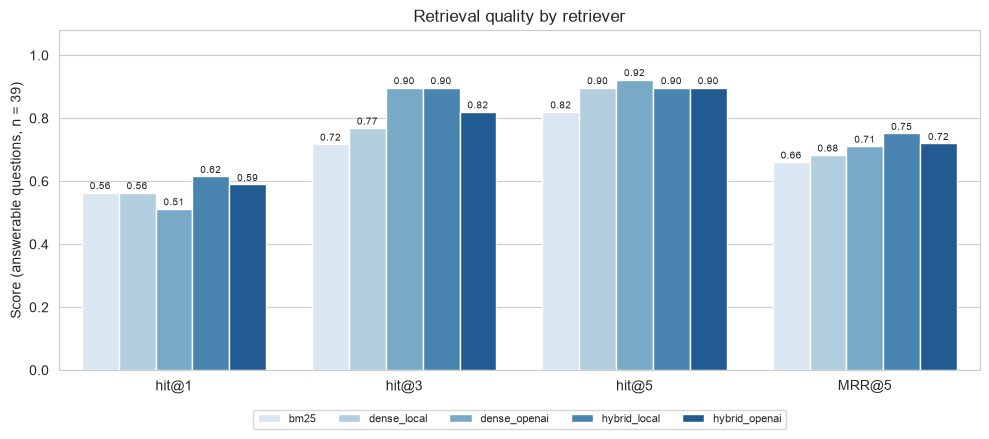

In [18]:
print(retrieval_results.round(4).to_string())

plot_df = (retrieval_results[["hit@1", "hit@3", "hit@5", "MRR@5"]]
           .reset_index(names="retriever")
           .melt(id_vars="retriever", var_name="metric", value_name="value"))
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=plot_df, x="metric", y="value", hue="retriever", ax=ax, palette="Blues")
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", fontsize=7, padding=1)
ax.set_ylim(0, 1.08)
ax.set_ylabel(f"Score (answerable questions, n = {len(ans_df)})")
ax.set_xlabel("")
ax.set_title("Retrieval quality by retriever")
ax.legend(title="", ncol=5, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plt.tight_layout()
plt.show()

### 6.3 Results - Hybrid search (H3)

| Retriever | hit@1 | hit@3 | hit@5 | MRR@5 | precision@5 | latency |
|---|---|---|---|---|---|---|
| bm25 | 0.5641 | 0.7179 | 0.8205 | 0.6611 | 0.3179 | 13.1 ms |
| dense_local | 0.5641 | 0.7692 | 0.8974 | 0.6833 | 0.2923 | 51.3 ms |
| dense_openai | 0.5128 | 0.8974 | **0.9231** | 0.7115 | 0.3436 | 319.6 ms |
| hybrid_local (BM25 + bge, RRF) | **0.6154** | 0.8974 | 0.8974 | **0.7521** | 0.3231 | 57.7 ms |
| hybrid_openai (BM25 + OpenAI, RRF) | 0.5897 | 0.8205 | 0.8974 | 0.7201 | **0.3538** | 323.5 ms |

- **H3 is partially confirmed.** On the primary metric, hit rate@5, neither hybrid beats the best dense retriever: both reach
  0.8974 against 0.9231 for `dense_openai`. Fusing BM25 into the OpenAI ranking actually lost three questions at hit@3 (0.8205
  vs. 0.8974, 32 vs. 35 of 39).
- On **ranking quality**, hybrid search wins: `hybrid_local` has the best MRR@5 of all five retrievers (0.7521, vs. 0.7115 for
  `dense_openai`) and the best hit@1 (0.6154, 24 of 39 questions with a relevant chunk ranked first). RRF promotes chunks that
  both BM25 and the embeddings agree on, which pushes exact matches on doses and figures to the top.
- `hybrid_local` adds this ranking gain to the free local model at 57.7 ms per query, and it was selected as the `rag_hybrid`
  configuration for generation (tied with `hybrid_openai` on hit@5, higher MRR@5).

### 6.4 Retrieval quality by question category

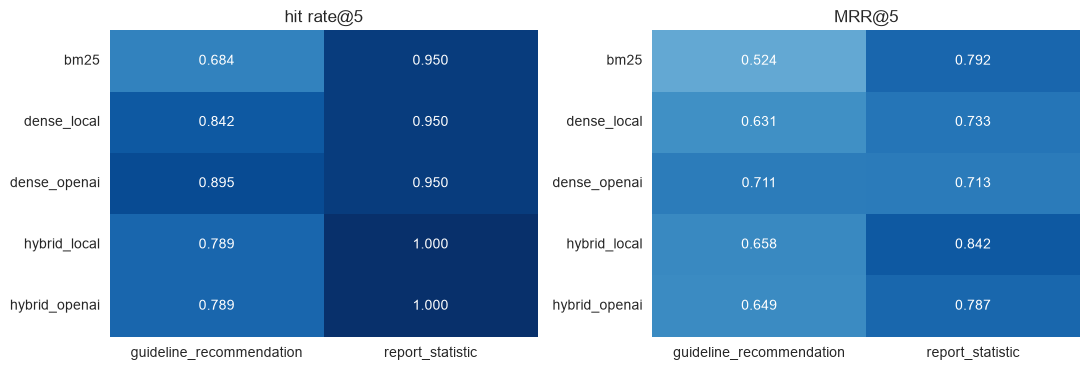

hit rate@5 by category:
               guideline_recommendation  report_statistic
bm25                             0.6842              0.95
dense_local                      0.8421              0.95
dense_openai                     0.8947              0.95
hybrid_local                     0.7895              1.00
hybrid_openai                    0.7895              1.00
Answerable questions missed by every retriever at k=5: ['G18']


In [19]:
by_cat = pd.DataFrame({
    (name, cat): retrieval_metrics(name, ans_df[ans_df["category"] == cat])
    for name in RETRIEVERS for cat in ["guideline_recommendation", "report_statistic"]
}).T
hit5_cat = by_cat["hit@5"].unstack(level=1)
mrr_cat = by_cat["MRR@5"].unstack(level=1)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, data, title in zip(axes, [hit5_cat, mrr_cat], ["hit rate@5", "MRR@5"]):
    sns.heatmap(data, annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()
print("hit rate@5 by category:")
print(hit5_cat.round(4).to_string())

# Questions that every retriever misses in the top 5
missed_by_all = [row.qid for row in ans_df.itertuples()
                 if not any(set(retrieved[n][row.qid][:5]) & row.relevant_chunks for n in RETRIEVERS)]
print("Answerable questions missed by every retriever at k=5:", missed_by_all)

### 6.4 Results - Retrieval by category

- **Report statistics are easy to retrieve; guideline recommendations are where retrievers differ.** On `report_statistic`
  questions every retriever reaches a hit rate@5 of at least 0.95 (19 of 20), and both hybrids reach 1.00. Figures such as
  "282 million" or "2164" are distinctive tokens, so even BM25 finds them. On `guideline_recommendation` questions the spread is
  wide: BM25 0.6842 (13 of 19), both hybrids 0.7895, `dense_local` 0.8421 and `dense_openai` 0.8947 (17 of 19). Guideline
  questions are paraphrased relative to the guideline wording ("co-deploying nets and spraying" vs. "co-deployment of ITNs and
  IRS"), which is where semantic matching earns its keep and where adding BM25 hurts.
- The whole H1 gap between the two embedding models comes from guideline questions (0.8947 vs. 0.8421); on report statistics they
  are tied at 0.95.
- **One question is missed by every retriever at k = 5: G18** ("If artesunate is not available for severe malaria, which
  parenteral alternative should be used?"). Its evidence sentence ("artemether should be used in preference to quinine") is short
  and sits on pages that also discuss many other severe-malaria options, so other artesunate passages outrank it. This is the
  kind of question a reranker or contextual retrieval (prepending a short summary to each chunk) is designed to fix.

## 7. Generation

### 7.1 Grounding prompt

The prompt is where the persona's main requirement ("an unsupported answer is worse than no answer") is enforced. The generator
is instructed to:
1. answer **only** from the numbered context passages,
2. **cite** every claim as `[document, p. N]`,
3. reply with a fixed abstention sentence when the context does not contain the answer, and
4. stay concise.

The closed-book baseline uses the same model with no context and is explicitly allowed to say "I don't know", so that H4 compares
two systems that both have a way to abstain.

In [20]:
ABSTAIN_TEXT = "Not found in the provided documents."

RAG_PROMPT = ChatPromptTemplate.from_messages([
    ("system",
     "You are an assistant for the head of a national malaria control programme. "
     "Answer the question using ONLY the numbered context passages from WHO documents. "
     "Cite the source of every factual claim with the document label and page shown in the passage header, "
     "in the form [World malaria report 2025, p. 24] or [WHO Guidelines for malaria, p. 17]. "
     "Never cite passage numbers such as [1] or [2]. "
     f"If the passages do not contain the answer, reply exactly: '{ABSTAIN_TEXT}' "
     "Do not use outside knowledge. Be concise (at most 120 words)."),
    ("human", "Context passages:\n\n{context}\n\nQuestion: {question}"),
])

CLOSED_BOOK_PROMPT = ChatPromptTemplate.from_messages([
    ("system",
     "You are an assistant for the head of a national malaria control programme. "
     "Answer the question from your own knowledge. If you do not know the answer, reply exactly: 'I don't know.' "
     "Be concise (at most 120 words)."),
    ("human", "Question: {question}"),
])


def format_context(chunk_id_list):
    blocks = []
    for i, cid in enumerate(chunk_id_list, start=1):
        meta = CHUNK_META[cid]
        blocks.append(f"[{i}] ({DOCS[meta['doc']]['label']}, p. {meta['page']})\n{CHUNK_TEXT[cid]}")
    return "\n\n".join(blocks)


print(RAG_PROMPT.format_messages(context="[1] (WMR 2025 executive summary, p. 6)\n...", question="...")[0].content)

You are an assistant for the head of a national malaria control programme. Answer the question using ONLY the numbered context passages from WHO documents. Cite the source of every factual claim with the document label and page shown in the passage header, in the form [World malaria report 2025, p. 24] or [WHO Guidelines for malaria, p. 17]. Never cite passage numbers such as [1] or [2]. If the passages do not contain the answer, reply exactly: 'Not found in the provided documents.' Do not use outside knowledge. Be concise (at most 120 words).


### 7.2 RAG chain

The chain follows the LangChain pattern `retriever -> prompt -> chat model`: retrieve the top 5 chunks, format them into the
prompt, call the generator. Four configurations are generated for all 45 questions:

| Configuration | Context given to the generator |
|---|---|
| `closed_book` | none (LLM knowledge only) |
| `rag_dense_local` | top 5 from `dense_local` |
| `rag_dense_openai` | top 5 from `dense_openai` |
| `rag_hybrid` | top 5 from the better hybrid retriever of section 6.3 (by hit rate@5, ties broken by MRR@5) |

Calls run in a small thread pool; each response is cached.

In [21]:
best_hybrid = (retrieval_results.loc[["hybrid_local", "hybrid_openai"]]
               .sort_values(["hit@5", "MRR@5"], ascending=False).index[0])
GEN_CONFIGS = {
    "closed_book": None,
    "rag_dense_local": "dense_local",
    "rag_dense_openai": "dense_openai",
    "rag_hybrid": best_hybrid,
}
print("rag_hybrid uses:", best_hybrid)


def generate(config, row):
    retriever = GEN_CONFIGS[config]
    if retriever is None:
        messages = CLOSED_BOOK_PROMPT.format_messages(question=row["question"])
        context_ids = []
    else:
        context_ids = retrieved[retriever][row["qid"]][:GEN_K]
        messages = RAG_PROMPT.format_messages(context=format_context(context_ids), question=row["question"])
    out = chat(GEN_MODEL, messages)
    return {"config": config, "qid": row["qid"], "answer": out["content"], "context_ids": context_ids,
            "gen_input_tokens": out["input_tokens"], "gen_output_tokens": out["output_tokens"],
            "gen_latency_s": out["latency_s"]}


jobs = [(cfg, row) for cfg in GEN_CONFIGS for row in eval_df.to_dict("records")]
with ThreadPoolExecutor(max_workers=6) as pool:
    gen_rows = list(pool.map(lambda job: generate(*job), jobs))
save_cache()

answers_df = pd.DataFrame(gen_rows).merge(eval_df[["qid", "category", "question", "reference_answer",
                                                   "key_terms", "relevant_chunks"]], on="qid")
print(f"Generated {len(answers_df)} answers ({len(GEN_CONFIGS)} configurations x {len(eval_df)} questions)")

rag_hybrid uses: hybrid_local


Generated 180 answers (4 configurations x 45 questions)


### 7.3 Side-by-side examples

In [22]:
for qid in ["R01", "G06", "U02"]:
    sub = answers_df[answers_df["qid"] == qid].set_index("config")
    print("=" * 110)
    print(f"{qid} | {sub['question'].iloc[0]}")
    print(f"Reference: {sub['reference_answer'].iloc[0]}")
    for cfg in ["closed_book", "rag_hybrid"]:
        print(f"\n--- {cfg} ---\n{sub.loc[cfg, 'answer']}")

R01 | How many malaria cases were estimated worldwide in 2024?
Reference: An estimated 282 million cases, in 80 malaria endemic countries.

--- closed_book ---
I don't know.

--- rag_hybrid ---
In 2024, there were an estimated 282 million malaria cases worldwide in 80 malaria endemic countries [World malaria report 2025, p. 3; p. 6; p. 24].
G06 | What primaquine dose should be given with an ACT to reduce P. falciparum transmission in low-transmission areas, and is G6PD testing required?
Reference: A single dose of 0.25 mg/kg bw primaquine; G6PD testing is not required (excluding pregnant women, infants under 1 month and women breastfeeding them).

--- closed_book ---
A single low dose of primaquine at 0.25 mg/kg body weight given alongside an ACT is recommended to reduce P. falciparum transmission in low-transmission areas. This dose effectively clears mature gametocytes and reduces transmission. According to WHO guidelines, G6PD testing is not required before administering this low do

### 7.3 Results - What the examples show

The three examples show the three behaviours that the evaluation measures:

- **R01 (a World malaria report 2025 statistic).** The closed-book model answers "I don't know.", which is honest: the 2024 estimate
  was published after its training data. RAG answers "282 million malaria cases worldwide in 80 malaria endemic countries" with
  three citations. This is H2 in miniature: for recent statistics, the documents are the only source of the answer.
- **G06 (a guideline recommendation).** Both answers give the right dose (0.25 mg/kg) and say that G6PD testing is not required,
  because this recommendation is old enough to be in the model's training data. But the closed-book answer adds unsourced
  advice ("caution is advised in populations with a high prevalence of G6PD deficiency"), while the RAG answer sticks to the
  guideline text and cites guideline pages 18, 180 and 181.
- **U02 (unanswerable: ivermectin).** The closed-book model writes a fluent, plausible paragraph about WHO's position on
  ivermectin, none of which can be traced to these documents. RAG replies "Not found in the provided documents." This is the H4
  behaviour, and the reason the persona needs grounding.

## 8. Answer Evaluation

### 8.1 AI-judge rubric

Each answer is graded by `gpt-4.1` (a larger model than the `gpt-4.1-mini` generator, to limit the **self-bias** of a model grading
its own outputs). The judge is set up as follows:

- **Categorical labels instead of numeric scores**, which LLM judges apply more consistently.
- **A rubric with examples**, and the judge writes a short justification **before** the label.
- **Two criteria**: **correctness** against the human reference answer
  (`correct`, `partially_correct`, `incorrect`, `abstained`) and **faithfulness**, i.e. local factual consistency with the
  retrieved context (`faithful`, `unfaithful`, `not_applicable` for closed-book answers and abstentions).
- For unanswerable questions, abstaining is the desired behaviour; any substantive answer counts as `incorrect` (a hallucination
  from the persona's point of view, even if it happens to be true in the outside world, because it cannot be traced to the
  documents).
- **Abstentions are detected deterministically.** Both prompts force a fixed refusal sentence ("Not found in the provided
  documents." / "I don't know."), so an answer containing it is labelled `abstained` regardless of the judge's label. In the first
  run the judge sometimes labelled a correct refusal to an unanswerable question as `correct` instead of `abstained`, which would
  have under-counted abstentions in H4.

In [23]:
class JudgeVerdict(BaseModel):
    reasoning: str = Field(description="One or two sentences justifying the labels.")
    correctness: Literal["correct", "partially_correct", "incorrect", "abstained"]
    faithfulness: Literal["faithful", "unfaithful", "not_applicable"]


JUDGE_SYSTEM = "You are a strict, impartial evaluator of a question-answering assistant about WHO malaria documents."
JUDGE_TEMPLATE = """Evaluate the ANSWER given by the assistant.

QUESTION: {question}

REFERENCE ANSWER (written by a human from the source documents): {reference}

CONTEXT GIVEN TO THE ASSISTANT (empty for a closed-book assistant):
{context}

ANSWER: {answer}

Rubric
1. correctness (compare the ANSWER with the REFERENCE ANSWER):
- correct: contains the key facts of the reference and nothing that contradicts it; extra consistent detail is fine.
- partially_correct: contains some key facts but misses an important part, or adds a minor error.
- incorrect: the key facts are wrong or contradict the reference; OR the reference says the question is not answerable from
  the documents and the assistant gives a substantive answer anyway.
- abstained: the assistant declines or says the information is not available / it does not know. When the reference says
  the question is not answerable from the documents, an abstention is the desired behaviour: label it 'abstained', not 'correct'.
Examples (question: global malaria deaths in 2024; reference: 610 000):
  "An estimated 610 000 deaths [World malaria report 2025, p. 24]" -> correct
  "About 600 000 deaths" -> incorrect
  "Not found in the provided documents." -> abstained

2. faithfulness (judge ONLY against the CONTEXT, never against your own knowledge):
- faithful: every factual claim in the answer is supported by the context.
- unfaithful: at least one factual claim is not supported by, or contradicts, the context.
- not_applicable: the context is empty, or the answer is an abstention."""

judge_llm = CHAT_MODELS[JUDGE_MODEL].with_structured_output(JudgeVerdict, include_raw=True)


def judge(row):
    context = format_context(row["context_ids"]) if row["context_ids"] else "(empty)"
    prompt = JUDGE_TEMPLATE.format(question=row["question"], reference=row["reference_answer"],
                                   context=context, answer=row["answer"])
    messages = [("system", JUDGE_SYSTEM), ("human", prompt)]
    key = cache_key("judge", JUDGE_MODEL, messages)
    if key not in LLM_CACHE:
        out = judge_llm.invoke(messages)
        usage = out["raw"].usage_metadata
        LLM_CACHE[key] = {**out["parsed"].model_dump(),
                          "input_tokens": usage["input_tokens"], "output_tokens": usage["output_tokens"]}
    v = LLM_CACHE[key]
    return {"correctness": v["correctness"], "faithfulness": v["faithfulness"], "judge_reasoning": v["reasoning"],
            "judge_input_tokens": v["input_tokens"], "judge_output_tokens": v["output_tokens"]}


with ThreadPoolExecutor(max_workers=6) as pool:
    verdicts = list(pool.map(judge, answers_df.to_dict("records")))
save_cache()
answers_df = pd.concat([answers_df.reset_index(drop=True), pd.DataFrame(verdicts)], axis=1)

# Deterministic abstention: the fixed refusal sentences override the judge label
ABSTAIN_RE = re.compile(r"not found in the provided documents|i don['’]t know", re.I)
answers_df["is_abstention"] = answers_df["answer"].str.contains(ABSTAIN_RE)
answers_df["judge_correctness"] = answers_df["correctness"]
overridden = (answers_df["is_abstention"] & (answers_df["correctness"] != "abstained")).sum()
answers_df.loc[answers_df["is_abstention"], "correctness"] = "abstained"
answers_df.loc[answers_df["is_abstention"], "faithfulness"] = "not_applicable"
print(f"Judge labels overridden to 'abstained' by the refusal-sentence rule: {overridden}\n")
print(answers_df.groupby("config")["correctness"].value_counts().unstack(fill_value=0).loc[list(GEN_CONFIGS)].to_string())

Judge labels overridden to 'abstained' by the refusal-sentence rule: 0

correctness       abstained  correct  incorrect  partially_correct
config                                                            
closed_book               6        9         20                 10
rag_dense_local           5       33          4                  3
rag_dense_openai          6       36          0                  3
rag_hybrid                6       34          2                  3


### 8.1 Results - Raw verdict counts

The refusal-sentence rule overrode **0** judge labels in this run: with the explicit rubric note, the judge labelled every refusal
as `abstained` by itself. Across all 45 questions:

| Configuration | Correct | Partially correct | Incorrect | Abstained |
|---|---|---|---|---|
| closed_book | 9 | 10 | 20 | 6 |
| rag_dense_local | 33 | 3 | 4 | 5 |
| rag_dense_openai | 36 | 3 | 0 | 6 |
| rag_hybrid | 34 | 3 | 2 | 6 |

The headline is visible before splitting by question type: the closed-book model gives an incorrect answer to 20 of 45 questions,
while the best RAG configuration (`rag_dense_openai`) gives **zero** incorrect answers. The next sections separate answerable from
unanswerable questions, because an abstention is a failure on the first and the right behaviour on the second.

### 8.2 Correctness and faithfulness by configuration (H2)

On the 39 answerable questions: **strict accuracy** counts only `correct`; **lenient accuracy** also counts `partially_correct`
as half a point. **Faithfulness** is computed over RAG answers that are not abstentions. The **false abstention rate** is the
share of answerable questions where the system said it could not find an answer that actually exists in the corpus, the
price paid for a cautious prompt.

Answerable questions (n = 39):
                  strict_accuracy  lenient_accuracy  incorrect_rate  false_abstention_rate  faithfulness
config                                                                                                  
closed_book                0.2308            0.3590          0.3846                 0.1282           NaN
rag_dense_local            0.8462            0.8846          0.0769                 0.0000        0.9744
rag_dense_openai           0.9231            0.9615          0.0000                 0.0000        0.9737
rag_hybrid                 0.8718            0.9103          0.0513                 0.0000        1.0000

Strict accuracy by category:
category          guideline_recommendation  report_statistic
config                                                      
closed_book                         0.4211              0.05
rag_dense_local                     0.8421              0.85
rag_dense_openai                    0.9474              0.90
rag_

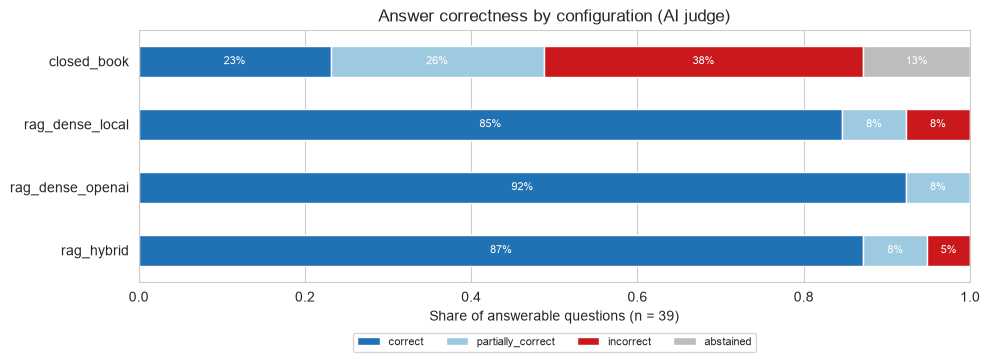

In [24]:
def answer_metrics(df):
    a = df[df["category"] != "unanswerable"]
    non_abst = a[a["correctness"] != "abstained"]
    rag_non_abst = non_abst[non_abst["faithfulness"] != "not_applicable"]
    return pd.Series({
        "strict_accuracy": (a["correctness"] == "correct").mean(),
        "lenient_accuracy": ((a["correctness"] == "correct") + 0.5 * (a["correctness"] == "partially_correct")).mean(),
        "incorrect_rate": (a["correctness"] == "incorrect").mean(),
        "false_abstention_rate": (a["correctness"] == "abstained").mean(),
        "faithfulness": (rag_non_abst["faithfulness"] == "faithful").mean() if len(rag_non_abst) else np.nan,
    })


overall = answers_df.groupby("config").apply(answer_metrics).loc[list(GEN_CONFIGS)]
print(f"Answerable questions (n = {answerable.sum()}):")
print(overall.round(4).to_string())

strict_by_cat = (answers_df[answers_df["category"] != "unanswerable"]
                 .assign(correct=lambda d: d["correctness"] == "correct")
                 .pivot_table(index="config", columns="category", values="correct", aggfunc="mean")
                 .loc[list(GEN_CONFIGS)])
print("\nStrict accuracy by category:")
print(strict_by_cat.round(4).to_string())

order = ["correct", "partially_correct", "incorrect", "abstained"]
dist = (answers_df[answers_df["category"] != "unanswerable"]
        .groupby("config")["correctness"].value_counts(normalize=True).unstack(fill_value=0)
        .reindex(columns=order, fill_value=0).loc[list(GEN_CONFIGS)])
ax = dist.plot(kind="barh", stacked=True, figsize=(10, 3.8),
               color=["#2171b5", "#9ecae1", "#cb181d", "#bdbdbd"])
for cont in ax.containers:
    ax.bar_label(cont, labels=[f"{w:.0%}" if w >= 0.04 else "" for w in cont.datavalues],
                 label_type="center", fontsize=8, color="white")
ax.set_xlabel(f"Share of answerable questions (n = {answerable.sum()})")
ax.set_ylabel("")
ax.set_title("Answer correctness by configuration (AI judge)")
ax.legend(ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18))
ax.invert_yaxis()
plt.tight_layout()
plt.show()

### 8.2 Results - Correctness and faithfulness (H2)

| Configuration | Strict accuracy | Lenient accuracy | Incorrect rate | False abstention rate | Faithfulness |
|---|---|---|---|---|---|
| closed_book | 0.2308 | 0.3590 | 0.3846 | 0.1282 | n/a |
| rag_dense_local | 0.8462 | 0.8846 | 0.0769 | 0.0000 | 0.9744 |
| rag_dense_openai | **0.9231** | **0.9615** | **0.0000** | 0.0000 | 0.9737 |
| rag_hybrid | 0.8718 | 0.9103 | 0.0513 | 0.0000 | **1.0000** |

| Strict accuracy by category | guideline_recommendation (19) | report_statistic (20) |
|---|---|---|
| closed_book | 0.4211 | 0.0500 |
| rag_dense_local | 0.8421 | 0.8500 |
| rag_dense_openai | **0.9474** | 0.9000 |
| rag_hybrid | 0.7895 | **0.9500** |

- **H2 is confirmed.** Strict accuracy rises from 23.08% closed-book (9 of 39) to between 84.62% and 92.31% with RAG, a gain of
  61.5 to 69.2 points. The effect is concentrated where the hypothesis predicted: on World malaria report statistics the
  closed-book model gets **1 of 20** right (5.00%), against 18 to 19 of 20 with RAG (90.00% to 95.00%). On guideline
  recommendations, which are older and partly in the model's training data, closed-book still reaches 42.11% (8 of 19), so the
  RAG gain there is smaller but still 36.8 to 52.6 points.
- Closed-book is not only less accurate, it is **confidently wrong**: 15 of its 39 answers (38.46%) are incorrect, and only 5
  (12.82%) are honest "I don't know" answers. For the persona, this is the dangerous combination.
- `rag_dense_openai` is the best end-to-end configuration: 36 of 39 correct, 3 partially correct, **no incorrect answer** and no
  false abstention. The retrieval gap of one question at hit@5 between OpenAI and local embeddings (section 6.2) becomes a
  three-question gap in strict accuracy (92.31% vs. 84.62%), because better-ranked context also helps the generator.
- `rag_hybrid` has the best faithfulness (100%: every non-abstaining answer is supported by its context) and the best accuracy on
  report statistics (95.00%), but drops to 78.95% on guideline recommendations. Its higher MRR in retrieval did not translate into
  better end-to-end accuracy.
- No RAG configuration ever abstained on an answerable question (false abstention rate 0.0000), so the cautious prompt did not
  cost any recall.

### 8.3 Abstention on unanswerable questions (H4)

In [25]:
unans = answers_df[answers_df["category"] == "unanswerable"]
abst = (unans.assign(abstained=lambda d: d["correctness"] == "abstained")
        .groupby("config")["abstained"].agg(["sum", "count", "mean"]).loc[list(GEN_CONFIGS)])
abst.columns = ["abstained", "questions", "abstention_rate"]
print(abst.round(4).to_string())

print("\nClosed-book answers to unanswerable questions that were NOT abstentions:")
for row in unans[(unans["config"] == "closed_book") & (unans["correctness"] != "abstained")].itertuples():
    print(f"- {row.qid}: {row.question}\n  -> {row.answer[:220]}")

print("\nRAG answers to unanswerable questions that were NOT abstentions:")
for row in unans[(unans["config"] != "closed_book") & (unans["correctness"] != "abstained")].itertuples():
    print(f"- {row.config} | {row.qid}: {row.question}\n  -> {row.answer[:260]}\n  judge: {row.judge_reasoning[:200]}")

                  abstained  questions  abstention_rate
config                                                 
closed_book               1          6           0.1667
rag_dense_local           5          6           0.8333
rag_dense_openai          6          6           1.0000
rag_hybrid                6          6           1.0000

Closed-book answers to unanswerable questions that were NOT abstentions:
- U01: What is the recommended dosing schedule of the dengue vaccine TAK-003?
  -> The recommended dosing schedule for the dengue vaccine TAK-003 (Qdenga) is two doses administered subcutaneously 3 months apart. The first dose is given at day 0, followed by the second dose at month 3. This two-dose sch
- U02: What does WHO recommend about mass ivermectin administration to reduce malaria transmission?
  -> WHO currently does not recommend mass ivermectin administration as a standalone intervention for malaria transmission reduction. While ivermectin has shown potential to reduce malar

### 8.3 Results - Abstention (H4)

| Configuration | Abstained | Unanswerable questions | Abstention rate |
|---|---|---|---|
| closed_book | 1 | 6 | 0.1667 |
| rag_dense_local | 5 | 6 | 0.8333 |
| rag_dense_openai | 6 | 6 | **1.0000** |
| rag_hybrid | 6 | 6 | **1.0000** |

- **H4 is confirmed.** The closed-book model abstained on only 1 of the 6 unanswerable questions (16.67%). On the other 5 it
  produced detailed, authoritative-sounding answers: a two-dose schedule for the dengue vaccine TAK-003, WHO "positions" on
  ivermectin, gene drive and Wolbachia mosquitoes, and a statement on chikungunya vaccines. Some may even be true in the outside
  world, but none can be traced to the programme's reference documents.
- `rag_dense_openai` and `rag_hybrid` abstained on all 6 (100%). `rag_dense_local` abstained on 5 of 6; on U05 (gene drive
  mosquitoes) it summarised a guideline passage that mentions genetically modified mosquitoes and noted there is "no explicit
  recommendation". That answer is grounded and arguably helpful, but under the strict rubric any substantive answer to an
  unanswerable question counts as a failure.
- The original seventh unanswerable question (vaccine price, now G19) is the counterpart lesson: all three RAG configurations
  found an "assumed price of US\$ 3 per dose" on guidelines page 162 that the human keyword search had missed. Grounded retrieval
  caught an error in the gold set.

### 8.4 Judge sanity check

An AI judge is itself a model and can be wrong, so its labels are cross-checked against a simple, judge-independent signal:
whether the answer contains all the `key_terms` of the reference (numbers, drug names, countries). Agreement between the two is
measured on all answerable answers that were not abstentions; disagreements are listed for inspection.

In [26]:
def key_terms_match(answer, key_terms):
    text = (answer.lower().replace("–", "-").replace("‑", "-").replace("—", "-")
            .replace(" ", " ").replace(" ", " "))
    return all(any(alt.strip() in text for alt in group.split("|")) for group in key_terms.split(";"))


chk = answers_df[(answers_df["category"] != "unanswerable") & (answers_df["correctness"] != "abstained")].copy()
chk["key_match"] = [key_terms_match(a, k) for a, k in zip(chk["answer"], chk["key_terms"])]
chk["judge_correct"] = chk["correctness"] == "correct"
agreement = (chk["key_match"] == chk["judge_correct"]).mean()
p_o = agreement
p_e = (chk["key_match"].mean() * chk["judge_correct"].mean()
       + (1 - chk["key_match"].mean()) * (1 - chk["judge_correct"].mean()))
kappa = (p_o - p_e) / (1 - p_e)
print(pd.crosstab(chk["judge_correct"].map({True: "judge: correct", False: "judge: not correct"}),
                  chk["key_match"].map({True: "key terms: all present", False: "key terms: missing"})).to_string())
print(f"\nAnswers compared: {len(chk)} | raw agreement: {agreement:.4f} | Cohen's kappa: {kappa:.4f}")

disagree = chk[chk["key_match"] != chk["judge_correct"]]
print(f"\nDisagreements ({len(disagree)}):")
for row in disagree.itertuples():
    print(f"- {row.config} | {row.qid} | judge={row.correctness} | key_match={row.key_match}")
    print(f"  answer: {row.answer[:200]}")
    print(f"  judge:  {row.judge_reasoning[:200]}")

key_match           key terms: all present  key terms: missing
judge_correct                                                 
judge: correct                         105                   7
judge: not correct                      12                  27

Answers compared: 151 | raw agreement: 0.8742 | Cohen's kappa: 0.6573

Disagreements (19):
- closed_book | G01 | judge=partially_correct | key_match=True
  answer: WHO recommends the following artemisinin-based combination therapies (ACTs) for treating uncomplicated P. falciparum malaria in children and adults: artemether-lumefantrine (AL), artesunate-amodiaquin
  judge:  The assistant's answer lists all the ACTs in the reference except for artesunate-pyronaridine, which is omitted. The rest of the information is accurate and consistent with the reference answer.
- closed_book | G03 | judge=correct | key_match=False
  answer: Adults and children with severe malaria should be treated promptly with intravenous (IV) or intramuscular (IM) ar

### 8.4 Results - Judge sanity check

| | Key terms all present | Key terms missing |
|---|---|---|
| **Judge: correct** | 105 | 7 |
| **Judge: not correct** | 12 | 27 |

On 151 non-abstaining answers to answerable questions, the judge and the key-term check agree on **87.42%** (Cohen's kappa
**0.6573**, substantial agreement). Reading the 19 disagreements shows they are explained by the rigidity of the lexical check,
not by judge errors:

- **Judge stricter (12 cases: key terms present, judge "not correct").** The answer has the right number but omits an important
  qualifier that the reference includes: G06 omits the exclusions for pregnant women and young infants, G19 gives "US\$ 3 per dose"
  without saying it is a modelling assumption, R19 gives the 21% fall without the 67% drop in US financing, and R09 lists Yemen as
  an African country. These are exactly the omissions a careful reviewer would flag.
- **Judge more lenient (7 cases: key terms missing, judge "correct").** The answer is right but paraphrased: "WHO does not
  recommend space spraying" instead of the key term "not recommended" (G14, four configurations), or "intramuscular artemether"
  without the word "quinine" (G18).

The judge therefore behaves like a strict human reviewer, and its labels are trustworthy enough to support H2 and H4.

### 8.5 Citation quality

For the persona, an answer is only usable if it can be verified, so citations are checked mechanically on every RAG answer that
is not an abstention:
- **formatted citation**: the answer contains at least one `[document label, p. N]` citation;
- **valid citations**: every cited (document, page) pair is one of the pages actually passed to the generator, i.e. no
  citation points to a page the model never saw.

In [27]:
LABEL_TO_DOC = {meta["label"]: doc_id for doc_id, meta in DOCS.items()}
BRACKET_RE = re.compile(r"\[([^\[\]]+)\]")
PAGES_RE = re.compile(r"\bpp?\.\s*([\d,\s\-–and]+)")


def label_to_doc(text):
    t = text.lower()
    if "executive summary" in t:
        return "wmr_2025_executive_summary"
    if "world malaria report" in t or "wmr" in t:
        return "world_malaria_report_2025"
    if "guideline" in t:
        return "who_guidelines_malaria"
    return None


def parse_citations(answer):
    """Parse [label, p. N], [label, pp. N, M] and [label, p. N; p. M; label2, p. K]; a bare page inherits the last label."""
    cited = []
    for group in BRACKET_RE.findall(answer):
        doc = None
        for part in group.split(";"):
            doc = label_to_doc(part) or doc
            for pages in PAGES_RE.findall(part):
                for page in re.findall(r"\d+", pages):
                    cited.append((doc, int(page)))
    return cited


def citation_check(answer, context_ids):
    cited = parse_citations(answer)
    context_pages = {(CHUNK_META[c]["doc"], CHUNK_META[c]["page"]) for c in context_ids}
    return pd.Series({"n_citations": len(cited),
                      "has_citation": len(cited) > 0,
                      "all_valid": len(cited) > 0 and all(c in context_pages for c in cited)})


cites = answers_df[(answers_df["config"] != "closed_book") & (answers_df["correctness"] != "abstained")].copy()
cites = pd.concat([cites, cites.apply(lambda r: citation_check(r["answer"], r["context_ids"]), axis=1)], axis=1)
citation_table = cites.groupby("config").agg(answers=("qid", "count"),
                                             mean_citations=("n_citations", "mean"),
                                             with_citation=("has_citation", "mean"),
                                             all_citations_valid=("all_valid", "mean"))
print(citation_table.round(4).to_string())


def classify_invalid(answer, context_ids):
    """Type of each cited (document, page) pair that is not among the pages given to the generator."""
    context_pages = {(CHUNK_META[c]["doc"], CHUNK_META[c]["page"]) for c in context_ids}
    types = []
    for doc, page in parse_citations(answer):
        if (doc, page) in context_pages:
            continue
        if any(p == page for _, p in context_pages):
            types.append("wrong document label (page exists in context under another document)")
        elif page <= GEN_K:
            types.append(f"passage number cited as a page (page <= {GEN_K}, not in context)")
        else:
            types.append("page not in context")
    return types


invalid_types = pd.Series([t for r in cites.itertuples() for t in classify_invalid(r.answer, r.context_ids)])
print("\nInvalid cited pages by type (all RAG configurations):")
print(invalid_types.value_counts().to_string())

bad = cites[~cites["all_valid"]]
print(f"\nAnswers with a missing or invalid citation: {len(bad)}")
for row in bad.itertuples():
    context_pages = sorted({(CHUNK_META[c]["doc"][:6], CHUNK_META[c]["page"]) for c in row.context_ids})
    print(f"- {row.config} | {row.qid}: cited={[(d[:6] if d else None, p) for d, p in parse_citations(row.answer)]} "
          f"context={context_pages}")
    print(f"  {row.answer[-160:]}")

                  answers  mean_citations  with_citation  all_citations_valid
config                                                                       
rag_dense_local        40          2.1500            1.0               0.8750
rag_dense_openai       39          2.3077            1.0               0.8718
rag_hybrid             39          2.3846            1.0               0.8205

Invalid cited pages by type (all RAG configurations):
passage number cited as a page (page <= 5, not in context)              10
wrong document label (page exists in context under another document)     8
page not in context                                                      3

Answers with a missing or invalid citation: 17
- rag_dense_local | G01: cited=[('who_gu', 170), ('who_gu', 171), ('who_gu', 173)] context=[('who_gu', 19), ('who_gu', 170), ('who_gu', 171), ('who_gu', 172), ('who_gu', 312)]
  oxine–pyrimethamine and artesunate-pyronaridine are not recommended for use in the first trimester of pr

### 8.5 Results - Citation quality

| Configuration | Answers checked | Mean citations per answer | With a formatted citation | All citations valid |
|---|---|---|---|---|
| rag_dense_local | 40 | 2.15 | 100.00% | 87.50% |
| rag_dense_openai | 39 | 2.31 | 100.00% | 87.18% |
| rag_hybrid | 39 | 2.38 | 100.00% | 82.05% |

| Type of invalid cited page (all RAG configurations) | Count |
|---|---|
| Passage number cited as a page (page 1 to 5, not in context) | 10 |
| Wrong document label (page exists in context under another document) | 8 |
| Page not in context | 3 |

- After making the format explicit in the prompt, **every** non-abstaining RAG answer carries at least one `[document, p. N]`
  citation, about 2.2 to 2.4 per answer.
- But 17 answers (14.4% of 118) cite at least one page the model was never given. The most common cause (10 cited pages) is
  **passage numbers leaking into citations**: the context blocks are numbered [1] to [5], and the model sometimes writes "p. 4" or
  "pp. 1, 3, 4" from those numbers. The second cause (8) is a **document mix-up**: correct page numbers from the *executive
  summary* attributed to the *World malaria report 2025*, two documents with very similar names. Only 3 cited pages are
  outside the context for no visible reason.
- Both causes come from how the context is formatted, not from invented facts (faithfulness is 97% to 100%). They point to two
  cheap fixes: label passages with letters or no numbers at all, and give the executive summary a clearly distinct label. A citation
  validator like this cell can also run in production to flag any answer whose citations do not match the retrieved pages.

### 8.6 Latency and cost per question

In [28]:
answers_df["gen_cost"] = [llm_cost(GEN_MODEL, i, o) for i, o in zip(answers_df["gen_input_tokens"], answers_df["gen_output_tokens"])]
answers_df["judge_cost"] = [llm_cost(JUDGE_MODEL, i, o) for i, o in zip(answers_df["judge_input_tokens"], answers_df["judge_output_tokens"])]

ops = answers_df.groupby("config").agg(
    mean_input_tokens=("gen_input_tokens", "mean"),
    mean_output_tokens=("gen_output_tokens", "mean"),
    mean_generation_s=("gen_latency_s", "mean"),
    p95_generation_s=("gen_latency_s", lambda s: s.quantile(0.95)),
    cost_per_question_usd=("gen_cost", "mean"),
).loc[list(GEN_CONFIGS)]
ops["retrieval_ms"] = [0.0 if GEN_CONFIGS[c] is None else 1000 * retrieval_latency[GEN_CONFIGS[c]] for c in ops.index]
ops["cost_per_1000_questions_usd"] = 1000 * ops["cost_per_question_usd"]
print(ops.round(5).to_string())

query_emb_tokens = sum(len(enc.encode(q)) for q in eval_df["question"]) * 2   # dense_openai + hybrid queries
run_cost = pd.Series({
    "openai_indexing": openai_index_cost,
    "openai_query_embeddings": query_emb_tokens * PRICES[OPENAI_EMB_MODEL]["input"] / 1e6,
    "generation_all_configs": answers_df["gen_cost"].sum(),
    "judging_all_configs": answers_df["judge_cost"].sum(),
})
run_cost["total"] = run_cost.sum()
print("\nCost of one full evaluation run from scratch (USD):")
print(run_cost.round(4).to_string())

                  mean_input_tokens  mean_output_tokens  mean_generation_s  p95_generation_s  cost_per_question_usd  retrieval_ms  cost_per_1000_questions_usd
config                                                                                                                                                        
closed_book                77.71111            84.82222            1.32522           2.52188                0.00017       0.00000                      0.16680
rag_dense_local          1262.77778            79.77778            1.08591           1.76706                0.00063      51.32190                      0.63276
rag_dense_openai         1273.08889            82.95556            1.05985           1.48534                0.00064     319.56091                      0.64196
rag_hybrid               1283.06667            83.04444            1.07637           1.68500                0.00065      57.70396                      0.64610



Cost of one full evaluation run from scratch (USD):
openai_indexing            0.0143
openai_query_embeddings    0.0000
generation_all_configs     0.0939
judging_all_configs        0.6139
total                      0.7222


### 8.6 Results - Latency and cost

| Configuration | Mean input tokens | Mean output tokens | Mean generation | p95 generation | Retrieval | Cost / 1,000 questions |
|---|---|---|---|---|---|---|
| closed_book | 78 | 85 | 1.33 s | 2.52 s | n/a | US\$ 0.17 |
| rag_dense_local | 1,263 | 80 | 1.09 s | 1.77 s | 51 ms | US\$ 0.63 |
| rag_dense_openai | 1,273 | 83 | 1.06 s | 1.49 s | 320 ms | US\$ 0.64 |
| rag_hybrid | 1,283 | 83 | 1.08 s | 1.69 s | 58 ms | US\$ 0.65 |

| Cost of one full evaluation run from scratch | US\$ |
|---|---|
| OpenAI indexing | 0.0143 |
| Query embeddings | 0.0000 |
| Generation (4 configurations x 45 questions) | 0.0939 |
| AI judging (180 answers) | 0.6139 |
| **Total** | **0.7222** |

- RAG multiplies the prompt size by about 16 (from 78 to roughly 1,270 input tokens) because of the 5 retrieved chunks, yet it
  still costs only **US\$ 0.63 to 0.65 per 1,000 questions** with `gpt-4.1-mini`.
- An answer takes about 1.1 seconds to generate (p95 under 1.8 s), plus 51 ms (local) to 320 ms (OpenAI) of retrieval, so the
  full RAG answer arrives in roughly 1.1 to 1.4 seconds. Generation time is similar with or without context, since output
  length (80 to 85 tokens) dominates.
- Evaluating is more expensive than answering: the `gpt-4.1` judge accounts for US\$ 0.6139 of the US\$ 0.7222 total (85%). The
  whole experiment, including indexing, costs less than a dollar, which makes it affordable to rerun the evaluation every time
  WHO publishes a new edition.

## 9. Error Analysis

Each component is evaluated separately so that a failure can be attributed to the right step.
Every answerable RAG answer that was not judged `correct` is classified as:

- **retrieval failure**: none of the 5 chunks given to the generator contains the evidence, so the generator never saw the answer;
- **generation failure**: the evidence was in the context, but the answer was wrong, incomplete or an abstention.

In [29]:
rag = answers_df[(answers_df["config"] != "closed_book") & (answers_df["category"] != "unanswerable")].copy()
rag["evidence_in_context"] = [bool(set(c) & r) for c, r in zip(rag["context_ids"], rag["relevant_chunks"])]
errors = rag[rag["correctness"] != "correct"].copy()
errors["failure_type"] = np.where(errors["evidence_in_context"], "generation failure", "retrieval failure")

err_table = (errors.groupby(["config", "failure_type"]).size().unstack(fill_value=0)
             .reindex(index=[c for c in GEN_CONFIGS if c != "closed_book"], fill_value=0))
err_table["total_not_correct"] = err_table.sum(axis=1)
print(err_table.to_string())

print("\nNot-correct answers of the RAG configurations:")
for row in errors.sort_values(["config", "qid"]).itertuples():
    print(f"- {row.config} | {row.qid} [{row.failure_type}] judge={row.correctness} faithfulness={row.faithfulness}")
    print(f"  Q: {row.question}")
    print(f"  A: {row.answer[:230]}")

failure_type      generation failure  retrieval failure  total_not_correct
config                                                                    
rag_dense_local                    4                  2                  6
rag_dense_openai                   3                  0                  3
rag_hybrid                         3                  2                  5



Not-correct answers of the RAG configurations:
- rag_dense_local | G06 [generation failure] judge=partially_correct faithfulness=faithful
  Q: What primaquine dose should be given with an ACT to reduce P. falciparum transmission in low-transmission areas, and is G6PD testing required?
  A: In low-transmission areas, a single dose of 0.25 mg/kg body weight primaquine should be given with an ACT to patients with P. falciparum malaria to reduce transmission. G6PD testing is not required for this dose [WHO Guidelines fo
- rag_dense_local | G12 [retrieval failure] judge=incorrect faithfulness=faithful
  Q: Does WHO recommend co-deploying insecticide-treated nets and indoor residual spraying in the same area?
  A: WHO guidance indicates that co-deploying ITNs and IRS may have limited additional utility in settings where there is optimal coverage with ITNs and these remain effective, as IRS may not significantly reduce malaria morbidity and 
- rag_dense_local | G19 [generation failure] judg

### 9.1 Results - Where the errors come from

| Configuration | Generation failures | Retrieval failures | Total not correct (of 39) |
|---|---|---|---|
| rag_dense_local | 4 | 2 | 6 |
| rag_dense_openai | 3 | 0 | 3 |
| rag_hybrid | 3 | 2 | 5 |

- **With OpenAI embeddings, retrieval is no longer the bottleneck**: all 3 of `rag_dense_openai`'s non-correct answers (G19, R09,
  R19) are generation failures with the evidence already in context. The local and hybrid configurations each lose 2 questions
  to retrieval (`rag_dense_local`: G12 and R20; `rag_hybrid`: G07 and G12).
- The 14 non-correct RAG answers fall into four failure modes:
  - **Omitted qualifiers (generation, partially correct): G06, G19, R19.** G06 gives the right primaquine dose but drops the
    exclusions (pregnant women, infants under 1 month); G19 gives "US\$ 3 per dose" without stressing it is a modelling
    assumption; R19 gives the 21% fall without the 67% drop in US financing. These recur across configurations and are risky for
    the persona, because the missing part is exactly the caveat that matters.
  - **A PDF layout trap (generation, incorrect): R14.** Page 94 of the report says "the coverage of both IPTp2 and IPTp3
    increased, from 54% to 55% and ...", and the extraction inserts a figure caption before the IPTp3 numbers. Both
    `rag_dense_local` and `rag_hybrid` reported the IPTp2 figure (55%) as IPTp3 coverage (45%).
  - **Misattribution of a list (generation, partially correct): R09.** The context lists An. stephensi detections in "Ethiopia
    (2016), Sri Lanka (2016), ... Yemen (2021), Ghana (2022)"; `rag_dense_openai` counted Yemen among the nine African countries.
  - **Missing context (retrieval): G07, G12, R20.** For G12, the retrieved chunks described ITNs and IRS as recommended
    interventions without the sentence advising against co-deploying them, and both `rag_dense_local` and `rag_hybrid` answered
    the opposite of the guideline. This is the most serious error type: a confident, cited, but wrong answer caused by missing
    context.
- Only 2 of the 14 were judged unfaithful (R14 for `rag_dense_local`, R09 for `rag_dense_openai`), and both misread figures that
  are present in the context. No error came from a figure that appears nowhere in the retrieved text.

## 10. Business Storytelling & Key Findings

### 10.1 Assistant demo

The final assistant wraps the recommended configuration (`rag_dense_openai`: OpenAI embeddings, top 5 chunks, `gpt-4.1-mini`)
in a single function: retrieve, generate, and return the answer with the list of sources (document and page) that the programme
team can open to verify. The same pipeline is available as a local chat interface in `app.py` (Streamlit), which reuses the
OpenAI Chroma collection built in section 4 and reads the API key from the user's own `.env`.

In [30]:
RETRIEVER_FINAL = GEN_CONFIGS["rag_dense_openai"]


def ask(question):
    context_ids = RETRIEVERS[RETRIEVER_FINAL](question)[:GEN_K]
    messages = RAG_PROMPT.format_messages(context=format_context(context_ids), question=question)
    answer = chat(GEN_MODEL, messages)["content"]
    sources = sorted({(DOCS[CHUNK_META[c]["doc"]]["label"], CHUNK_META[c]["page"]) for c in context_ids})
    return answer, sources


for q in ["What does WHO recommend for preventing malaria in pregnant women living in endemic areas?",
          "How much funding did malaria control receive in 2024 and where did it come from?"]:
    answer, sources = ask(q)
    print("Q:", q)
    print("A:", answer)
    print("Retrieved sources:", "; ".join(f"{d} p.{p}" for d, p in sources))
    print()
save_cache()

Q: What does WHO recommend for preventing malaria in pregnant women living in endemic areas?
A: WHO recommends intermittent preventive treatment in pregnancy (IPTp) for pregnant women of all gravidities living in malaria-endemic areas. Specifically, sulfadoxine-pyrimethamine (SP) is used for IPTp starting as early as possible in the second trimester (not before week 13), with doses given at least one month apart, aiming for at least three doses during pregnancy. IPTp-SP reduces malaria burden and adverse pregnancy outcomes. However, IPTp-SP is contraindicated in HIV+ pregnant women receiving co-trimoxazole prophylaxis. For HIV+ pregnant women, dihydroartemisinin-piperaquine is not recommended for IPTp. Antenatal care visits are key platforms for delivering IPTp, though access barriers exist [World malaria report 2025, p. 93; WHO Guidelines for malaria, pp. 30, 103, 11, 5].
Retrieved sources: WHO Guidelines for malaria p.11; WHO Guidelines for malaria p.30; WHO Guidelines for malaria p.

Q: How much funding did malaria control receive in 2024 and where did it come from?
A: In 2024, total funding for malaria control and elimination was estimated at US$ 3.9 billion, a slight decline from US$ 4.0 billion in 2023 [World malaria report 2025, p. 75]. This funding included US$ 23.3 billion in domestic resources and US$ 45.4 billion in international funding accumulated between 2000 and 2024 [World malaria report 2025, p. 75]. The sources of funding in 2024 comprised government-reported contributions, international donors, and estimated patient care delivery costs [World malaria report 2025, p. 148]. Specific donor disbursement data by agency and recipient country are detailed in the OECD CRS and WHO/MNT estimates [World malaria report 2025, p. 77].
Retrieved sources: World malaria report 2025 p.75; World malaria report 2025 p.77; World malaria report 2025 p.148; World malaria report 2025 p.150



### 10.1 Results - Demo

Both demo questions are open-ended and not part of the evaluation set, and together they show what the assistant does well and
why its answers must be verified:

- **Malaria prevention in pregnancy.** The assistant combines passages from four retrieved pages into one coherent answer: IPTp
  for all gravidities, SP starting as early as possible in the second trimester but not before week 13, doses at least one month
  apart aiming for at least three, the contraindication for HIV+ women on co-trimoxazole, and the recommendation against
  dihydroartemisinin-piperaquine IPT for women living with HIV. The content is right, but the citation list includes "p. 5", a
  page that was not retrieved: a live example of the passage-number leak measured in section 8.5.
- **2024 funding.** The headline figure is right (US\$ 3.9 billion, down from US\$ 4.0 billion in 2023, World malaria report
  page 75). But this time retrieval did not bring back the executive summary page with the 56% international vs. 44% domestic
  split, so the answer does not really say "where it came from"; instead it quotes multi-year cumulative totals (US\$ 23.3
  billion domestic, US\$ 45.4 billion international) in a sentence that reads as if they were part of the 2024 amount.

This is the workflow the persona needs, and also its limit: the assistant finds the right pages and drafts a sourced answer in
about a second, and the retrieved-source list lets the team open the exact pages to verify. It is a drafting and search tool, not
a source to quote without checking, which is exactly the operating rule recommended in 10.4.

### 10.2 Hypotheses and results

### 10.2 Results - Hypotheses scorecard

| # | Hypothesis | Result |
|---|---|---|
| H1 | OpenAI embeddings retrieve better than the local `bge-small` model | **Confirmed, by a small margin.** hit rate@5 0.9231 vs. 0.8974 (one question of 39) and MRR@5 0.7115 vs. 0.6833; end to end, strict accuracy 92.31% vs. 84.62%. The local model is 6.2 times faster per query (51 ms vs. 320 ms) but 20.5 times slower to index (813 s vs. 40 s). |
| H2 | RAG answers are more often correct than closed-book answers, especially for World malaria report statistics | **Confirmed.** Strict accuracy 84.62% to 92.31% with RAG vs. 23.08% closed-book; on report statistics, 90.00% to 95.00% vs. 5.00% (1 of 20). |
| H3 | Hybrid search (BM25 + dense, RRF) beats the best dense-only retriever | **Partially confirmed.** Not on hit rate@5 (0.8974 for both hybrids vs. 0.9231 for `dense_openai`), but `hybrid_local` has the best MRR@5 (0.7521) and hit@1 (0.6154). End to end, `rag_hybrid` (87.18%) did not beat `rag_dense_openai` (92.31%). |
| H4 | RAG abstains on unanswerable questions more often than closed-book | **Confirmed.** 83.33% to 100% abstention with RAG vs. 16.67% closed-book (1 of 6); the closed-book model gave confident answers to 5 of the 6. |

### 10.3 Key findings

### 10.3 Results - Key findings

- **Grounding changes the risk profile more than any model choice.** Without retrieval, the same LLM was wrong on 38.46% of
  answerable questions and invented answers to 5 of 6 unanswerable ones. With RAG, the best configuration had **0 incorrect
  answers in 39** and abstained on **all 6** unanswerable questions.
- **The documents are the only source for recent figures.** On World malaria report 2025 statistics, closed-book accuracy is
  5.00% (1 of 20) against 90.00% to 95.00% with RAG. Any assistant for this programme must retrieve; a bigger or newer model
  alone would still lag the latest report.
- **The paid embedding model wins, but only just.** OpenAI embeddings found the evidence for one more question at hit@5
  (0.9231 vs. 0.8974) and led to 3 more correct answers end to end (92.31% vs. 84.62%), for US\$ 0.0143 per full index. The free
  local model is a credible fallback, not a free lunch: it took 13.6 minutes to index the corpus.
- **Hybrid search improved ranking, not answers.** `hybrid_local` ranked the right chunk first most often (hit@1 0.6154, MRR@5
  0.7521) and was the best on report statistics (95.00%), but its end-to-end accuracy (87.18%) stayed below dense OpenAI
  retrieval. Retrieval metrics are necessary, but they have to be confirmed end to end.
- **The remaining errors are omissions and misreadings, not inventions.** Faithfulness stayed between 97% and 100%. The 14
  non-correct RAG answers came from dropped qualifiers, a sentence split by a figure caption, a misattributed list and missing
  passages; none used a figure that appears nowhere in the retrieved text.
- **Citations are always present but not always exact.** 100% of RAG answers cite sources, yet 14.4% cite at least one page
  the model did not see, mostly by turning passage numbers into page numbers or mixing up the report and its executive summary.
  Both are formatting problems with cheap fixes.
- **It is cheap.** About US\$ 0.64 per 1,000 questions and 1.1 to 1.4 seconds per answer. The full evaluation, including judging,
  costs US\$ 0.72, so the system can be re-evaluated every time WHO publishes a new edition.

### 10.4 Recommendation for the programme

### 10.4 Results - Recommended architecture and operating rules

**Recommended configuration:** `rag_dense_openai`: `text-embedding-3-small` retrieval (top 5 chunks of 1,000 characters),
`gpt-4.1-mini` generation with the grounding prompt, Chroma as the vector store. It had the highest strict accuracy (92.31%), no
incorrect answers, no false abstentions and 100% abstention on unanswerable questions, at about US\$ 0.64 per 1,000 questions.

**When to choose the local alternative (`rag_hybrid` with `bge-small`):** if per-query calls to an external embedding API are
not allowed, or query latency matters more than the last few points of accuracy (58 ms vs. 320 ms retrieval). Since generation
still uses OpenAI, the local model does not remove the external dependency; it only removes it from retrieval.

**Operating rules for the programme (what the evaluation supports, and what it does not):**
1. **Use it to find and draft, not to publish.** With 92.31% strict accuracy and 3 of 39 answers missing a qualifier, every
   statement that goes into a policy brief or a clinical instruction must be checked against the cited page. The citations make
   that a one-minute check instead of a manual search through 727 pages. As an illustrative assumption, if a manual look-up takes
   10 minutes, 1,000 questions represent about 167 staff hours, against US\$ 0.64 of API cost plus the verification time.
2. **Treat "Not found in the provided documents." as a real answer.** It means the question is outside the WHO corpus, which is
   where the closed-book model hallucinated most.
3. **Dosing and eligibility questions need the full recommendation text.** Across configurations, the partial answers on
   clinical questions (G06 primaquine, G07 relapse regimens) dropped exclusions or one of the regimens. For these questions the
   user should always open the cited page.
4. **Add the citation validator from section 8.5 as a guardrail**, and fix the two citation-formatting causes before deployment.
5. **Re-run this evaluation for every new edition** of the guidelines or the report (US\$ 0.72 per run), extending the question
   set with real questions from programme staff.

## 11. Conclusions & Next Steps

### 11.1 Conclusions and next steps

**Conclusions.** A RAG assistant over the WHO guidelines for malaria and the World malaria report 2025 answered 92.31% of a
hand-labelled question set fully correctly, gave no incorrect answers, cited its sources on every answer and declined every
question the documents could not answer, for well under one US cent per 10 questions. The same LLM without retrieval was correct
on 23.08% of answerable questions, and on 5.00% of the recent report statistics, and it produced confident answers to 5 of 6
questions that have no answer in the corpus. For a national malaria programme, the business question is answered with a
qualified yes: the assistant can replace manual PDF search for routine look-ups, provided every answer that feeds an official
document is verified against its cited page. On the second question, the paid OpenAI embeddings retrieved slightly better than
the free local model (one question at hit@5, three questions end to end), at a negligible cost.

**Limitations.**
- The evaluation set has 45 questions (39 answerable), so one question moves any rate by 2.56 points; differences of one or two
  questions between configurations are suggestive, not statistically established.
- Questions were written by one person from the documents; real programme questions will be more ambiguous and multi-part.
- One gold label (G19) was corrected after the first run, as documented in section 5.1.
- Correctness relies on an AI judge; it agreed with an independent key-term check on 87.42% of answers (kappa 0.6573), but it is not
  a panel of human experts.
- Text inside charts, maps and some tables is lost or garbled by PDF extraction (section 2.3), so figure-only facts are out of
  reach.

**Next steps.**
1. **Fix the citation format**: drop passage numbers from the context headers and give the executive summary a distinct label,
   then re-measure citation validity (section 8.5).
2. **Reranking**: retrieve 20 chunks and rerank them with a cross-encoder before passing 5 to the generator, targeting the
   retrieval misses (G07, G12, G18).
3. **Contextual retrieval**: prepend a short LLM-generated description of the section to each chunk, so
   that recommendation chunks carry their section title.
4. **Chunk-size experiment** (500 vs. 1,000 vs. 1,500 characters) on retrieval metrics, which is cheap with the local model.
5. **Table and figure extraction** for the World malaria report (layout-aware PDF parsing), to make chart and table facts
   retrievable.
6. **A chat interface** (Streamlit or Gradio) on top of `ask()`, with conversation memory and query rewriting for follow-up
   questions.
7. **A larger, human-validated evaluation set** built from real questions asked by programme staff.